## Import Libraries

In [1]:
## import libraries
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import sys
import itertools
from scipy.stats import gaussian_kde
import pyreadr  # For reading RData files
import json

# Ensure the src directory is in the Python path
src_dir = os.path.abspath("../src")
if src_dir not in sys.path:
    sys.path.append(src_dir)

import pnetwork.sow as sow
import pnetwork.utils as utils
import pnetwork.pr_sampling as pr_sampling
import pnetwork.udd as udd

from matplotlib import colormaps, cm
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import seaborn as sns
import itertools
import math
from matplotlib.gridspec import GridSpec

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## Figure parameters

In [2]:
# FigureS1: Precipitation Projections
s1_setup = "../data/processed/setup.json"
s1_noaa_file = "../data/processed/precipitation/atlas14_Norfolk.txt"
s1_projection_folder = "../data/processed/precipitation/projection/results"
s1_figure_name = 'FigureS1.pdf'
s1_return_period = 10
s1_year = 2075



# FigureS2: Number of SOWs for convergence in reliability estimation
s2_setup = "../data/processed/setup.json"
s2_samples_folder = "../results/SOWs_output/conv_num/"
s2_figure_name = "FigureS2.pdf"
s2_network = "37"
s2_num_SOWs = [1, 12, 25, 50, 125, 175, 250, 1250]
s2_num_resample = [20,20,20,20,20,20,20,4]
s2_rel = 0.95
s2_seeds = 5


# FigureS3: Convergence in NSGA-II optimization in HV
s3_network = '5'
s3_folder = f"../results/SOWs_output/{s3_network}/PipeByPipe_conv"
s3_seeds = [1,2,3,4,5]
s3_gaSettings = 'pop_100_ftol_0.005'
s3_figure_name = "FigureS3.pdf"
s3_n_objs = 2

# FigureS4: Convergence in NSGA-II optimization plotting cost vs reliability
s4_network = '5'
s4_folder = f"../results/SOWs_output/{s4_network}/PipeByPipe_conv"
s4_seeds = [1,2,3,4,5]
s4_gaSettings = 'pop_100_ftol_0.005'
s4_figure_name = "FigureS4.pdf"
s4_n_objs = 2
s4_bf = f"../results/SOWs_output/{s4_network}/BruteForce_4obj/pf.csv"


# FigureS6: Stress testing of UDD designs
s6_swmm_folder = "../results/SOWs_output/"
s6_figure_name = "FigureS6.pdf"
s6_networks = ["5", "9", "16", "23", "37", "49", "62", "76", "84", "100", "150"]
s6_estimated_scenario = False


# FigureS7-1: SystemSF
s7_n_obj = 4
s7_network = "37"
s7_name = 'FigureS7.pdf'
s7_swmm_folder = "../results/SOWs_output/"

# FigureS7-2: FunctionSF
s7_fsf_network = ['49', '62', '76', '84']
s7_fsf_name = 'FigureS7_FSF.pdf'
s7_fsf_folder = "../results/SOWs_output/"
s7_fsf_path = {net: f'../results/SOWs_output/{net}/FunctionSF_4obj/pf.csv' for net in s7_fsf_network}



# FigureS8: Reliability-cost rade-offs across different approaches
s8_figure_name = 'FigureS8.pdf'
s8_n_obj = 4
s8_paths = {
    '5': {
        'PBP': '../results/SOWs_output/5/PipeByPipe_4obj/pop_100_ftol_0.005/pf.csv',
        'FunctionSF': '../results/SOWs_output/5/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/5/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/5/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/5/UDD_20prec/udd.json'
    },
    '9': {
        'PBP': '../results/SOWs_output/9/PipeByPipe_4obj/pop_180_ftol_0.005/pf.csv',
        'FunctionSF': '../results/SOWs_output/9/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/9/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/9/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/9/UDD_20prec/udd.json'
    },
    '16': {
        'PBP': '../results/SOWs_output/16/PipeByPipe_4obj/pop_320_ftol_0.005/pf.csv',
        'FunctionSF': '../results/SOWs_output/16/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/16/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/16/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/16/UDD_20prec/udd.json'
    },
    '23': {
        'PBP': '../results/SOWs_output/23/PipeByPipe_4obj/pop_460_ftol_0.005/pf.csv',
        'FunctionSF': '../results/SOWs_output/23/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/23/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/23/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/23/UDD_20prec/udd.json'
    },
    '37':{
        'FunctionSF': '../results/SOWs_output/37/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/37/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/37/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/37/UDD_20prec/udd.json'
    },
    '49':{
        'FunctionSF': '../results/SOWs_output/49/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/49/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/49/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/49/UDD_20prec/udd.json'
    },
    '62':{
        'FunctionSF': '../results/SOWs_output/62/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/62/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/62/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/62/UDD_20prec/udd.json'
        },
    '76':{
        'FunctionSF': '../results/SOWs_output/76/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/76/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/76/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/76/UDD_20prec/udd.json'
    },
    '84':{
        'FunctionSF': '../results/SOWs_output/84/FunctionSF_4obj/pf.csv',
        'SystemSF': '../results/SOWs_output/84/SystemSF_4obj/pf.csv',
        'UDD': '../results/SOWs_output/84/UDD/udd.json',
        'UDD_20prec': '../results/SOWs_output/84/UDD_20prec/udd.json'
    }
}

# FigureS9
s9_figure_name = "FigureS9.pdf"
s9_networks = ['5', '9', '16', '23', '37', '49', '62', '76', '84']
s9_paths = s8_paths

# FigureS10:
s10_sobol_json_path_all = "../results/SOWs_output/sobol/sobol_analysis_network_37_aggregated_65536_seed_1.json"
s10_sobol_json_path = "../results/SOWs_output/sobol/sobol_analysis_network_37_65536_seed_1.json"
s10_figure_name = "FigureS10.pdf"

# FigureS11: PBP with different number of size choices
s11_figure_name = "FigureS11.pdf"
s11_network = '5'
s11_folder = f"../results/SOWs_output/{s11_network}/PipeByPipe_size_choice"
s11_choice_list = [[2,4],[3,3],[2,5],[3,4],[3,5],[4,4],[5,4],[4,5], [5,5]]
s11_gaSettings = 'pop_100_ftol_0.0075'

## Source code / Functions

### S1: Rainfall projection distribution

In [3]:
def read_noaa_data(noaa_file, rtn_value=10):
    """
    Read NOAA precipitation data from a file.

    Args:
        noaa_file (str): Path to the NOAA precipitation data file.
        rtn_value (int): Return period to extract.

    Returns:
        tuple: (low, mean, high) precipitation values for the given return period.
    """
    df = pd.read_csv(noaa_file, sep='\s+', comment='/', skiprows=1, names=['rtn', 'noaa', 'low', 'high'])
    row = df[df['rtn'] == rtn_value]
    if not row.empty:
        noaa = row['noaa'].values[0]
        low = row['low'].values[0]
        high = row['high'].values[0]
        return low, noaa, high
    else:
        print(f"rtn={rtn_value} not found in NOAA file.")
        return None, None, None

def read_rainfall_data(model_name, year_name, return_period=10, source_file='data/processed/precipitation/projection/results'):
    """
    Reads projection results from an RData file for a given climate model and year.

    Args:
        model_name (str): The name of the climate model.
        year_name (int or str): The year of the projection.
        return_period (int): The return period in years.
        source_file (str): The base directory where projection results are stored.

    Returns:
        np.ndarray: Rainfall intensity samples.
    """
    file_name = f"{source_file}/{model_name}/nonstat_param{year_name}.RData"
    rainfall_data = pyreadr.read_r(file_name)
    
    # Extract GEV parameters
    xi_df = rainfall_data['xi_chain']
    mu_df = rainfall_data['muproj_chain']
    sigma_df = rainfall_data['sigma_chain']

    # Compute rainfall intensity using the return level function
    rainfall_df = pr_sampling.myreturnlevel(return_period, mu_df, sigma_df, xi_df)
    rainfall_samples = np.array(rainfall_df).flatten()
    return rainfall_samples

def plot_prec_projections(
        setup,
        noaa_file,
        projection_folder,
        figure_name,
        return_period=10,
        year=2075
    ):
    """
    Plot precipitation projections from GCMs and NOAA Atlas 14 reference.

    Args:
        setup (str): Path to UDD setup JSON file.
        noaa_file (str): NOAA Atlas 14 precipitation data file.
        projection_folder (str): Folder containing precipitation projection data.
        figure_name (str): Name of the figure file to save.
        return_period (int): Return period for precipitation projections.
        year (int): Year for precipitation projections.
    """
    # Load NOAA precipitation data
    noaa_low, noaa_mean, noaa_high = read_noaa_data(noaa_file, rtn_value=return_period)
    if noaa_low is None or noaa_mean is None or noaa_high is None:
        print("Error reading NOAA data. Exiting.")
        return

    # Load scenario definitions
    setup_data = utils.load_json(setup)
    climate_models = setup_data["climate_models"]

    plt.figure(figsize=(10, 6.18))  # Golden ratio aspect ratio

    
    for model in climate_models:
        samples = read_rainfall_data(model, year, return_period, projection_folder)
        kde = gaussian_kde(samples)
        x_grid = np.linspace(min(samples), max(samples), 500)
        y_density = kde(x_grid)
        y_density /= y_density.sum() * (x_grid[1] - x_grid[0])  # Normalize area under curve to 1
        plt.plot(x_grid, y_density, label=model)

    # Plot NOAA reference as vertical lines
    plt.axvline(noaa_mean, color='k', linestyle='--')
    ax = plt.gca()
    y_max = ax.get_ylim()[1]
    x_min, x_max = ax.get_xlim()
    ax.annotate(
        "NOAA Atlas 14",
        xy=(noaa_mean, -4),  # point on x-axis
        xytext=(noaa_mean + 0.06 * (x_max - x_min), -3.2),  # bottom, horizontal text
        ha='left',
        va='bottom',
        fontsize=16,
        color='k',
        arrowprops=dict(arrowstyle='->', color='k', lw=1.2)
    )
    plt.ylim(-4, y_max * 1.1)

    plt.xlabel(f'Projected {return_period}-yr rainfall intensity in {year} (in/hr)', fontsize=18)
    plt.ylabel('Probability Density', fontsize=18)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.legend(fontsize=18)
    plt.tight_layout()
    plt.savefig(figure_name, dpi=300)
    plt.show()

### S2: Number of SOWs

In [4]:
def read_data(samples_folder, seeds, num_resample=20, scenarios=None):
    """
    Read sample data from the specified folder and combine into a single numpy array.

    Args:
        samples_folder (str): Path to the folder containing sample files.
        seeds (list): List of random seeds used in sampling.
        num_resample (int): Number of resample folders to read.
        scenarios (list): List of (climate, aging) scenario tuples.

    Returns:
        np.ndarray: Data array of shape (num_seed*num_resample, num_scenarios, ...).
    """
    data = []
    for seed in range(seeds):
        for i in range(num_resample):
            results = []
            for climate, aging in scenarios:
                file_name = f"{climate}_{aging}_results.npy"
                file_path = os.path.join(samples_folder, f"resample_{i}_seed_{seed}", file_name)
                if os.path.exists(file_path):
                    loaded_data = np.load(file_path, allow_pickle=True)
                    results.append(loaded_data)
                else:
                    print(f"File not found: {file_path}")
            data.append(results)
    return np.array(data)

def read_results_all_scenarios(data, rel=80):
    """
    Aggregate results for all scenarios and resamples.

    Args:
        data (np.ndarray): Data array of shape (num_resample, num_scenarios, num_sample).
        rel (float): Reliability threshold.

    Returns:
        np.ndarray: Array of averaged results for each resample.
    """
    num_seed_resample, num_scenarios, num_sample = data.shape
    results = []
    for resample in range(num_seed_resample):
        resample_results = []
        for scenario in range(num_scenarios):
            result_per_scenario = sow.read_result(
                data[resample, scenario, :], num_sample, num_all_sample=num_sample, rel=rel
            )
            resample_results.append(result_per_scenario)
        resample_results = np.mean(np.array(resample_results), axis=0)
        resample_results[2] = resample_results[2] * 100  # Convert robustness to percentage
        results.append(resample_results)
    return np.array(results)

def determine_sow_n_rel(objs_resample, num_SOWs, scenarios=None):
    """
    Print convergence diagnostics for SOW sample sizes.

    Args:
        objs_resample (dict): Dictionary of results arrays keyed by SOW count.
        num_SOWs (list): List of SOW counts.
        scenarios (list): List of scenario tuples.
    """
    num_scenarios = len(scenarios)
    objs_values = objs_resample.copy()

    for metric_ind in [0, 1]:  # Loop through 0: reliability, 1:flooding_volume
        print(f"\nConvergence diagnostics for metric index {metric_ind} ({'Reliability' if metric_ind == 0 else 'Flooding Volume'}):")
        box_data = [objs_values[j][:, metric_ind] for j in num_SOWs]

        # +-2.5% for reliability, +-10% for flooding volume
        mean_value = np.mean(box_data[-1])
        lower_bound = mean_value - 0.025 * mean_value if metric_ind == 0 else mean_value - 0.1 * mean_value
        upper_bound = mean_value + 0.025 * mean_value if metric_ind == 0 else mean_value + 0.1 * mean_value
        print(f"Reference mean value: {mean_value}, Lower bound: {lower_bound}, Upper bound: {upper_bound}")

        for j in num_SOWs:
            num_samples = j * num_scenarios
            ci_lower = np.percentile(objs_values[j][:, metric_ind], 2.5)
            ci_upper = np.percentile(objs_values[j][:, metric_ind], 97.5)
            if lower_bound <= ci_lower and ci_upper <= upper_bound:
                print(f"Sample size {j} ({num_samples} SOWs) meets the precision requirement with 95% CI: [{ci_lower}, {ci_upper}]")
            else:
                print(f"Sample size {j} does not meet the precision requirement. 95% CI: [{ci_lower}, {ci_upper}]")


def plot_sow_count_rel(setup, samples_folder, figure_name, network, num_SOWs, num_resample, rel=80, seeds=1):
    """
    Plot reliability and flooding volume as functions of the number of SOWs.

    Args:
        setup (str): Path to setup JSON file.
        samples_folder (str): Folder containing SOW samples.
        network (str): Network name.
        num_SOWs (list): List of SOW counts.
        num_resample (list): List of resample counts for each SOW count.
        rel (float): Reliability threshold.
        figure_name (str): Name of the figure file to save.
    """
    # Load scenario definitions
    setup_data = utils.load_json(setup)
    climate_models = setup_data["climate_models"]
    aging_models = setup_data["aging_models"]
    scenarios = list(itertools.product(climate_models, aging_models))
    num_scenarios = len(scenarios)

    objs_resample = {}
    print("Starting reading data...")
    for i, j in zip(num_SOWs, num_resample):
        samples_folder_i = os.path.join(samples_folder, f"{network}_{i}")
        if not os.path.exists(samples_folder_i):
            print(f"Samples folder does not exist: {samples_folder_i}")
            print(f"No samples found for {network} with {i} SOWs")
            objs_resample[i] = None
            continue
        samples_folder_i_data = os.path.join(samples_folder_i, network)
        udd_result_i = read_data(samples_folder=samples_folder_i_data, seeds=seeds, num_resample=j, scenarios=scenarios)
        objs_resample[i] = read_results_all_scenarios(udd_result_i, rel=rel)
    print("Data reading completed.")

    # Prepare data for plotting
    objs_values = objs_resample.copy()
    fig, axes = plt.subplots(2, 1, figsize=(12, 10))

    # Metric information: (index, ylabel, ylim, tolerance)
    metrics = [
        (0, "Reliability (%) ", (0, 100), 0.025), #against\n24-hr 10-yr rainfall event in 2075
        (1, "Flooding Volume (k ft$^3$)", (0, 30), 0.1),
    ]

    panel_labels = ["(a)", "(b)"]

    for ax_idx, (metric_ind, ylabel, ylim, tolerance) in enumerate(metrics):
        ax = axes[ax_idx]
        scale_factor = 1000.0 if metric_ind == 1 else 1.0
        box_data = [objs_values[j][:, metric_ind] / scale_factor for j in num_SOWs]

        mean_value = np.mean(box_data[-1])
        lower_bound = mean_value * (1 - tolerance)
        upper_bound = mean_value * (1 + tolerance)

        ax.axhline(
            mean_value,
            color="black",
            linestyle="--",
            zorder=1,
            
        )
        #label=f"Mean when sample size is {num_SOWs[-1] * num_scenarios}",
        print(f"\n{panel_labels[ax_idx]} - Metric {metric_ind}:")
        print(f"Reference mean value: {mean_value}, Lower bound: {lower_bound}, Upper bound: {upper_bound}")

        # Draw a rectangle behind the plot
        ax.add_patch(
            plt.Rectangle(
                (0.5, lower_bound),
                len(num_SOWs) + 0.5,
                upper_bound - lower_bound,
                color="lightgray",
                alpha=0.7,
                zorder=0,
                
            )
            #label="Acceptable Region",
        )
        ax.annotate(
        "Acceptable Region",
        xy=(5.5, upper_bound*0.98), 
        xytext=(5.65,upper_bound*1.2),  
        ha='left',
        va='bottom',
        fontsize=22,
        color='k',
        arrowprops=dict(arrowstyle='->', color='k', lw=1.2)
        )

        for idx, j in enumerate(num_SOWs):
            num_samples = j * num_scenarios
            ci_lower = np.percentile(objs_values[j][:, metric_ind], 2.5) / scale_factor
            ci_upper = np.percentile(objs_values[j][:, metric_ind], 97.5) / scale_factor
            mean_j = np.mean(objs_values[j][:, metric_ind]) / scale_factor
            if lower_bound <= ci_lower and ci_upper <= upper_bound:
                print(
                    f"Sample size {j} ({num_samples} SOWs) meets the precision requirement "
                    f"with 95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]"
                )
            else:
                print(f"Sample size {j} does not meet the precision requirement. 95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

            ax.vlines(
                x=idx + 1,
                ymin=ci_lower,
                ymax=ci_upper,
                colors="red",
                linestyles="-",
                linewidth=2,
                label="95% Confidence Interval" if idx == 0 else "",
            )
            ax.scatter(idx + 1, mean_j, color="blue", marker="D", s=40, label="Mean Estimate" if idx == 0 else "")

            cap_width = 0.2
            ax.hlines(y=ci_lower, xmin=idx + 1 - cap_width / 2, xmax=idx + 1 + cap_width / 2, colors="red", linewidth=2)
            ax.hlines(y=ci_upper, xmin=idx + 1 - cap_width / 2, xmax=idx + 1 + cap_width / 2, colors="red", linewidth=2)
        

        ax.set_xlabel("Number of SOWs", size=22)
        ax.set_ylabel(ylabel, size=22)
        ax.tick_params(axis="y", labelsize=22)
        ax.tick_params(axis="x", labelsize=22)
        ax.set_xticks(range(1, len(num_SOWs) + 1))
        ax.set_xlim(0.5, len(num_SOWs) + 0.5)
        ax.set_ylim(ylim)
        ax.set_xticklabels([j * num_scenarios for j in num_SOWs], size=22)
        ax.text(-0.12, 1, panel_labels[ax_idx], transform=ax.transAxes, fontsize=22, va="top", ha="left")
        if ax_idx == 0:
            ax.legend(loc="lower right", fontsize=22)

    plt.tight_layout()
    plt.savefig(figure_name, dpi=300)
    plt.show()

### S3: Convergence of NSGAII


In [5]:

def plot_ga_hv(folder, seeds, gaSettings, n_objs=2, figure_name="nsga2_conv.pdf", cost_vs_reliability=False):
    hvs = []
    results = []
    for seed in seeds:
        file_path = os.path.join(folder, f"seed_{seed}_{n_objs}", f"{gaSettings}", "PipeByPipe.json")
        if os.path.exists(file_path):
            with open(file_path, 'r') as f:
                data = json.load(f)
                hv_list = data.get('hypervolume', None)
                hv = []
                for item in hv_list:
                    hv += item

                hvs.append(hv)
        else:
            print(f"File not found: {file_path}")
    
    
    hv_max = max(max(hv) for hv in hvs)
    hvs = [[i/hv_max*100 for i in hv] for hv in hvs]
    pop = int(gaSettings.split('_')[1])
    
    plt.figure(figsize=(10, 6))
    for idx, hv in enumerate(hvs):
        evaluations = [i * pop for i in range(1, len(hv) + 1)]
        plt.plot(evaluations, hv, label=f'Seed {seeds[idx]}')
    plt.xlabel('Number of Evaluations', fontsize=22)
    plt.ylabel('% Hypervolume', fontsize=22)
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.legend(fontsize=20, loc='lower right')
    plt.tight_layout()
    plt.savefig(figure_name, dpi=300)
    plt.show()
    
        

### S4: Convergence in Objectives Space

In [6]:
def pf_df(df, objs, mins = [0,1]):
    # Filter the DataFrame with rows that are Pareto-optimal based on the objectives in 'objs'.
    # if mins[i] is 1, then the objectives are to be minimized. If 0, then the objectives are to be maximized.
    """
    Args:
        df (pd.DataFrame): Input DataFrame containing the data.
        objs (list): List of objective column names to consider for Pareto filtering.
        mins (list, optional): List indicating whether to minimize (1) or maximize (0) each objective. Defaults to [0, 1].
    Returns:
        pd.DataFrame: Filtered DataFrame containing only Pareto-optimal rows.
    """
    values = df[objs].to_numpy()
    n = len(values)
    is_pareto = np.ones(n, dtype=bool)

    for i in range(n):
        if not is_pareto[i]:
            continue

        for j in range(n):
            if i == j:
                continue

            better_or_equal = True
            strictly_better = False

            for k, minimize in enumerate(mins):
                if minimize == 1:
                    if values[j, k] > values[i, k]:
                        better_or_equal = False
                        break
                    if values[j, k] < values[i, k]:
                        strictly_better = True
                else:
                    if values[j, k] < values[i, k]:
                        better_or_equal = False
                        break
                    if values[j, k] > values[i, k]:
                        strictly_better = True

            if better_or_equal and strictly_better:
                is_pareto[i] = False
                break

    return df[is_pareto].copy()

In [7]:
def plot_ga_obj(folder, seeds, gaSettings, n_objs=2, figure_name="Figure", cost_vs_reliability=False, bf_path=None):
    hvs = []
    results = []
    for seed in seeds:
        folder_path = os.path.join(folder, f"seed_{seed}_{n_objs}", f"{gaSettings}", "csv_results")
        if os.path.exists(folder_path):
            cleaned_files = sorted(
                [f for f in os.listdir(folder_path) if f.endswith("_cleaned.csv")]
            )
            if cleaned_files:
                cleaned_file = cleaned_files[0]
                cleaned_path = os.path.join(folder_path, cleaned_file)
                df = pd.read_csv(cleaned_path)
                n_obj_list = [f'f{i}' for i in range(1, n_objs + 1)]
                objs = df[n_obj_list].values
                results.append(df)
            else:
                print(f"No '_cleaned.csv' file found in: {folder_path}")
        else:
            print(f"Folder not found: {folder_path}")
    
    
    plt.figure(figsize=(10, 6))
    if bf_path:
        bf_df = pd.read_csv(bf_path)
        bf_df_clean = pf_df(bf_df, ['f4', 'f1'], mins=[1,0])
        plt.scatter(bf_df_clean['f4']/1000, bf_df_clean['f1'], s = 80, label='Brute Force', color='white', edgecolor='black')

    for idx, df in enumerate(results):
        plt.scatter(df[n_obj_list[-1]]/1000, -df[n_obj_list[0]], label=f'Seed {seeds[idx]}')

    plt.scatter(
        0,
        100,
        marker="$\u2764\ufe0f$",
        s=500,
        color="Green",
        zorder=0,
        clip_on=False
    )
    plt.text(
        20,
        85,
        "Utopian Point",
        ha="center",
        va="bottom",
        fontsize=18,
        color="Green",
        zorder=1
    )
    # Add arrow pointing towards utopian point
    plt.annotate(
        '',
        xy=(1, 98),  # Point to utopian point
        xytext=(20, 90),  # Start arrow from this position
        arrowprops=dict(
            arrowstyle='->',
            color='green',
            lw=2
        )
    )
    plt.xlabel('Upfront Cost (k$)', fontsize=22)
    plt.ylabel('Reliability (%)', fontsize=22)
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.legend(fontsize=20, loc='lower right')
    plt.xlim(left=0)
    plt.ylim(top=100)
    plt.tight_layout()
    
    plt.savefig(figure_name, dpi=300)
    plt.show()

### S6: Stress test

In [8]:
def read_udd_data(swmm_folder, network):
    """
    Read UDD data from JSON file including reliability and scenario data.

    Args:
        swmm_folder (str): Folder containing SWMM results.
        network (str): Network name.

    Returns:
        dict: Dictionary containing reliability, reliability_per_scenario, and scenario info.
    """
    file_path = os.path.join(swmm_folder, network, 'UDD', 'udd.json')
    
    if os.path.exists(file_path):
        try:
            with open(file_path, 'r') as f:
                data = json.load(f)
                return {
                    'reliability': data.get('reliability', None),
                    'reliability_per_scenario': data.get('reliability_per_scenario', None),
                    'scenario': data.get('scenario', None)
                }
        except (json.JSONDecodeError, KeyError) as e:
            print(f"Error reading {file_path}: {e}")
            return None
    else:
        print(f"Warning: {file_path} does not exist.")
        return None


def estimate_missing_reliability(reliabilities, networks):
    """
    Estimate missing reliability values using polynomial fitting.

    Args:
        reliabilities (list): List of reliability values (may contain None).
        networks (list): List of network names.

    Returns:
        list: Complete list of reliability values with estimates for missing data.
    """
    # Extract valid data points
    valid_indices = [i for i, r in enumerate(reliabilities) if r is not None]
    
    if len(valid_indices) < 2:
        print("Warning: Not enough data points for estimation. Using default values.")
        return [85.0 if r is None else r for r in reliabilities]
    
    valid_networks = [int(networks[i]) for i in valid_indices]
    valid_reliabilities = [reliabilities[i] for i in valid_indices]
    
    # Fit polynomial (degree 2 or less based on available data)
    degree = min(2, len(valid_indices) - 1)
    coeffs = np.polyfit(valid_networks, valid_reliabilities, degree)
    
    # Estimate missing values
    estimated_reliabilities = []
    smooths_networks = np.linspace(int(networks[0]), int(networks[-1]), 50)
    smooths_reliabilities = np.polyval(coeffs, smooths_networks)
    for i, network in enumerate(networks):
        if reliabilities[i] is not None:
            estimated_reliabilities.append(reliabilities[i])
        else:
            network_size = int(network)
            estimated_value = np.polyval(coeffs, network_size)
            # Clamp reliability between 0 and 100
            estimated_value = max(0, min(100, estimated_value))
            estimated_reliabilities.append(estimated_value)
            print(f"Estimated reliability for network {network}: {estimated_value:.2f}%")
    
    return estimated_reliabilities, smooths_networks, smooths_reliabilities


def get_scenario_info(udd_data_list):
    """
    Extract scenario information from UDD data.
    
    Args:
        udd_data_list (list): List of UDD data dictionaries.
        
    Returns:
        tuple: (climate_models, aging_models, scenario_labels)
    """
    # Get scenario info from first available dataset
    for data in udd_data_list:
        if data and data['scenario']:
            scenario_data = data['scenario']
            # Extract unique climate and aging models from scenario data
            climate_models = set(scenario[0] for scenario in scenario_data)
            aging_models = set(scenario[1] for scenario in scenario_data)
            scenario_labels = ['_'.join(map(str, scenario)) for scenario in scenario_data]
            return climate_models, aging_models, scenario_labels


def plot_udd_reliability(figure_name, networks, swmm_folder, show_plot=False, estimated_scenario=False):
    """
    Plot the UDD reliability for different network sizes.

    Args:
        figure_name (str): Figure name.
        networks (list): List of network names.
        swmm_folder (str): Folder containing SWMM results.
        show_plot (bool): Whether to display the plot.
        estimated_scenario (bool): Whether to show estimated scenario data.
    """
    # Read UDD data
    udd_data_list = []
    reliabilities = []
    valid_networks = []
    
    print("Reading UDD data...")
    for network in networks:
        data = read_udd_data(swmm_folder, network)
        udd_data_list.append(data)
        
        if data and data['reliability'] is not None:
            reliabilities.append(data['reliability'])
            valid_networks.append(network)
            print(f"Network {network}: {data['reliability']:.2f}% reliability")
        else:
            reliabilities.append(None)
    
    # Get scenario information
    climate_models, aging_models, scenario_labels = get_scenario_info(udd_data_list)
    
    # Create single plot
    fig, ax = plt.subplots(1, 1, figsize=(14, 14/1.618))  # Golden ratio for aesthetics
    
    # Process overall reliability data
    reliabilities_with_estimates, smooths_networks, smooths_reliabilities = estimate_missing_reliability(reliabilities, networks)
    network_sizes = [int(n) for n in networks]
    
    # Separate actual vs estimated data for overall reliability
    actual_networks = []
    actual_reliabilities = []
    estimated_networks = []
    estimated_reliabilities = []
    
    for i, network in enumerate(networks):
        if network in valid_networks:
            actual_networks.append(network_sizes[i])
            actual_reliabilities.append(reliabilities_with_estimates[i])
        else:
            estimated_networks.append(network_sizes[i])
            estimated_reliabilities.append(reliabilities_with_estimates[i])
    
    # Process scenario data
    # Define colors for climate models and edge styles for aging models
    colors = plt.cm.Set1(np.linspace(0.2, 0.8, len(climate_models)))
    
    # Create color mapping
    color_map = {climate: colors[i] for i, climate in enumerate(climate_models)}
    
    # Create edge style mapping for aging models
    aging_list = list(aging_models)
    edge_map = {}
    for i, aging in enumerate(aging_list):
        edge_map[aging] = {
            'edgecolors': 'black' if i % 2 == 0 else 'none',
            'linewidth': 1 if i % 2 == 0 else 0
        }
    
    # Collect scenario data for all networks
    scenario_data = {}
    networks_with_scenario_data = []
    
    # First pass: collect actual scenario data
    for i, network in enumerate(networks):
        data = udd_data_list[i]
        if data and data['reliability_per_scenario'] is not None:
            networks_with_scenario_data.append(network)
            for j, reliability in enumerate(data['reliability_per_scenario']):
                if j < len(scenario_labels):
                    scenario = scenario_labels[j]
                    if scenario not in scenario_data:
                        scenario_data[scenario] = {
                            'networks': [], 
                            'reliabilities': [],
                            'estimated_networks': [],
                            'estimated_reliabilities': []
                        }
                    scenario_data[scenario]['networks'].append(network_sizes[i])
                    scenario_data[scenario]['reliabilities'].append(reliability)
    
    # Second pass: estimate missing scenario data for each scenario
    for scenario in scenario_data:
        actual_networks_for_scenario = scenario_data[scenario]['networks']
        actual_reliabilities_for_scenario = scenario_data[scenario]['reliabilities']
        
        # Create list of all networks with None for missing data
        all_scenario_reliabilities = []
        for network in networks:
            network_size = int(network)
            if network_size in actual_networks_for_scenario:
                # Find the reliability for this network
                idx = actual_networks_for_scenario.index(network_size)
                all_scenario_reliabilities.append(actual_reliabilities_for_scenario[idx])
            else:
                all_scenario_reliabilities.append(None)
        
        # Estimate missing values for this scenario
        estimated_scenario_reliabilities, _, _ = estimate_missing_reliability(all_scenario_reliabilities, networks)
        
        # Separate estimated values
        for i, network in enumerate(networks):
            network_size = int(network)
            if network_size not in actual_networks_for_scenario:
                scenario_data[scenario]['estimated_networks'].append(network_size)
                scenario_data[scenario]['estimated_reliabilities'].append(estimated_scenario_reliabilities[i])
    
    # PLOT SCENARIO DATA FIRST (as background)
    for scenario, data in scenario_data.items():
        # Parse scenario to get climate and aging model
        scenario_parts = scenario.split('_')
        climate_model = scenario_parts[0] if len(scenario_parts) > 0 else aging_list[0]
        aging_model = scenario_parts[1] if len(scenario_parts) > 1 else aging_list[0]
        
        # Find matching climate and aging models
        if climate_model not in climate_models:
            climate_model = aging_list[0]
        if aging_model not in aging_models:
            aging_model = aging_list[0]
        
        color = color_map[climate_model]
        edge_style = edge_map[aging_model]
        
        # Plot actual scenario data points (smaller, more transparent)
        if data['networks']:
            ax.scatter(data['networks'], data['reliabilities'], 
                      color=color, s=80, marker='o', alpha=0.4, 
                      edgecolors=edge_style['edgecolors'], 
                      linewidth=edge_style['linewidth'], zorder=2)
        
        # Plot estimated scenario data points (smaller, more transparent)
        if data['estimated_networks'] and estimated_scenario == True:
            ax.scatter(data['estimated_networks'], data['estimated_reliabilities'], 
                      color=color, s=90, marker='o', alpha=0.3, 
                      edgecolors=edge_style['edgecolors'], 
                      linewidth=edge_style['linewidth'], zorder=1)
    
    
    # Plot actual mean data points (most prominent)
    if actual_networks:
        ax.scatter(actual_networks, actual_reliabilities, 
                  color='red', s=180, marker='x', label='Actual Mean Reliability', 
                  linewidth=3, zorder=5)
        

    plt.plot(smooths_networks, smooths_reliabilities, color='red', linestyle='--', linewidth=2, label='Estimated Reliability', zorder=3)
    ax.text(89, 62, 'Estimated\nReliability', color='red', fontsize=18)
    


    # Plot one horizontal line at 100% reliability as the "Aimed Reliability of the design" with dashed style and an annotation
    ax.axhline(y=100, color='green', linestyle='--', linewidth=2, alpha=0.7, label='Aimed Reliability of the Design', zorder=0)
    ax.text(20, 101, 'Neglecting climate change & deep uncertainty', color='green', fontsize=18)
    
    # Apply log scale to x-axis
    ax.set_xscale('log')
    
    # Customize plot with larger fonts
    ax.set_xlabel('Number of Pipes (log-scale)', fontsize=20)
    ax.set_ylabel('Reliability (%) against\n24-hr 10-yr rainfall event in 2075', fontsize=20)
    # Set x-axis limits and ticks for log scale
    ax.set_xlim(min(network_sizes) * 0.8, max(network_sizes))
    ax.set_ylim(0, 108)
    
    # Customize x-axis ticks for better readability
    ax.set_xticks([5, 10, 20, 50, 100])
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
    
    # Grid and other customizations

    ax.tick_params(axis='both', labelsize=18)
    
    # Create comprehensive legend
    climate_models_orders = ['CanESM2-CanRCM4',
                             'ACCESS-ESM1-5',
                             'BCC-CSM2-MR',
                             'MPI-ESM1-2-HR']
    # Climate model handles (for scenario data)
    climate_handles = [plt.Line2D([0], [0], color=color_map[climate], marker='o', linestyle='None',
                                 markersize=8, alpha=0.6, markeredgewidth=0,
                                 label=f'{climate}') 
                      for climate in climate_models_orders]
    
    # Add climate legend with title
    legend2 = ax.legend(handles=climate_handles, title='Scenarios (Climate Models)', fontsize=18, 
                       loc='lower center', frameon=True, fancybox=True, shadow=False,
                       bbox_to_anchor=(0.2, 0.02), ncol=1)
    legend2.get_title().set_fontsize(18)  # Set title font size
    
    # Aging model handles (edge styles)
    aging_handles = []
    aging_labels = {'udd': 'UD', 'stat': 'STAT'}
    aging_list = ['udd', 'stat']
    for aging in aging_list:
        edge_style = edge_map[aging]
        aging_handles.append(plt.Line2D([0], [0], color='gray', marker='o', linestyle='None',
                                       markersize=8, alpha=0.6, 
                                       markeredgecolor=edge_style['edgecolors'] if edge_style['edgecolors'] != 'none' else 'gray',
                                       markeredgewidth=edge_style['linewidth'] if edge_style['linewidth'] > 0 else 0,
                                       label=f'{aging_labels[aging]}'))
    
    # Add aging legend with title
    legend3 = ax.legend(handles=aging_handles, title='Scenarios (Aging Models)', fontsize=18, 
                       loc='lower right', frameon=True, fancybox=True, shadow=False,
                       bbox_to_anchor=(0.7, 0.02), ncol=1)
    legend3.get_title().set_fontsize(18)  # Set title font size
    
    # Add all legends back to the plot
    ax.add_artist(legend2)  # Climate scenarios
    
    # Adjust layout
    plt.tight_layout()
    
    # Save the figure
    
   
    plt.savefig(figure_name, dpi=300, bbox_inches='tight')
    
    
    # Print summary statistics
    print("\n" + "="*50)
    print("UDD RELIABILITY SUMMARY")
    print("="*50)
    print(f"Networks analyzed: {len(networks)}")
    print(f"Networks with valid overall data: {len(valid_networks)}")
    print(f"Networks with scenario data: {len(networks_with_scenario_data)}")
    
    if actual_reliabilities:
        print(f"Average overall reliability: {np.mean(actual_reliabilities):.2f}%")
        print(f"Min overall reliability: {np.min(actual_reliabilities):.2f}%")
        print(f"Max overall reliability: {np.max(actual_reliabilities):.2f}%")
    
    print(f"\nScenario information:")
    print(f"Climate models: {list(climate_models)}")
    print(f"Aging models: {list(aging_models)}")
    print(f"Total scenarios: {len(scenario_labels)}")
    
    # Print estimation summary for each scenario
    print(f"\nEstimation summary per scenario:")
    for scenario, data in scenario_data.items():
        actual_count = len(data['networks'])
        estimated_count = len(data['estimated_networks'])
        print(f"  {scenario}: {actual_count} actual, {estimated_count} estimated")
    
    # Show plot if requested
    if show_plot:
        plt.show()
    
    return reliabilities_with_estimates, network_sizes

### S7-1: SystemSF

In [9]:
from matplotlib.ticker import FuncFormatter

def read_result(path, n_obj, objs, sf_name = [], negative = True, 
                cost_per_ft = True, total_length = 1, report=False):
    """
    Read optimization results from a CSV file and process the data for plotting.

    Args:
        path (str): Path to the CSV file containing optimization results.
        n_obj (int): Number of objectives in the optimization problem.
        objs (list): List of objective names corresponding to the columns in the CSV.
        sf_name (list, optional): List of additional column names for system/function safety factors (default: []).
        negative (bool, optional): Whether to negate reliability and robustness values (default: True).
        cost_per_ft (bool, optional): Whether to calculate cost per foot instead of total cost (default: True).
        total_length (float, optional): Total length of the pipes for cost per foot calculation (default: 1).
        report (float or bool, optional): If a float is provided, it represents a reliability threshold for reporting a specific design. If False, no specific design is reported (default: False).
    """
    
    data = pd.read_csv(path)
    ocols = [f"f{i+1}" for i in range(n_obj)]
    if len(sf_name) == 0:
        df = pd.DataFrame(data, columns= ocols)
    else:
        df = pd.DataFrame(data, columns= ocols + sf_name)
    cols_rename = {ocols[i]: objs[i] for i in range(n_obj)}
    df.rename(columns = cols_rename, inplace=True)
    if negative:
        df['Reliability (%)'] = -df['Reliability (%)']
        if 'Robustness (%)' in df.columns:
            df['Robustness (%)'] = -df['Robustness (%)']
    if cost_per_ft:
        df['Cost ($/ft)'] = df['Cost ($)'] / total_length
    else:
        df['Cost (k$)'] = df['Cost ($)'] / 1000
    
    df.sort_values(by='Reliability (%)', ascending=False, inplace=True)
    df = df.reset_index(drop = True)
    

    if report:
        # Find the design with reliability >= report that has the lowest cost
        larger_df = df[df['Reliability (%)'] >= report]
        cost_col = 'Cost ($/ft)' if 'Cost ($/ft)' in df.columns else 'Cost (k$)' if 'Cost (k$)' in df.columns else 'Cost ($)'
        if not larger_df.empty:
            closest_idx = larger_df[cost_col].idxmin()
            closest_design = larger_df.loc[closest_idx]
        else:
            # If no design meets the threshold, find the closest one overall
            closest_idx = (df['Reliability (%)'] - report).abs().idxmin()
            closest_design = df.loc[closest_idx]
        print(f"Design with reliability >= {report}% and lowest cost:")
        print(closest_design)
        return df, closest_design
    else:
        return df, None

def plot_obj_sf(figure_name, n_obj, network, SystemSF, UDD, UDD_20prec, swmm_folder, cost_per_ft = True, sf_range = (0.78, 1.22)):

    
    if n_obj == 2:
        obj_name = ['Reliability (%)', 'Cost ($)']
        if cost_per_ft:
            obj_name_plot = ['Reliability (%)','Cost ($/ft)']
        else:
            obj_name_plot = obj_name
    else:
        obj_name = ['Reliability (%)', 'Robustness (%)',  'System overflow volume (ft^3)', 'Cost ($)']
        if cost_per_ft:
            obj_name_plot = ['Reliability (%)', 'Robustness (%)',  'System overflow volume (ft^3)', 'Cost ($/ft)']
        else:
            obj_name_plot = obj_name


    # Get total length for cost per ft calculation
    if UDD or cost_per_ft:
        udd_path = os.path.join(swmm_folder, f'{network}/UDD/udd.json')
        if os.path.exists(udd_path):
            with open(udd_path, 'r') as f:
                udd_data = json.load(f)
                total_length = udd_data.get('total_pipe_length', 1)
        else:
            total_length = 1
    else:
        total_length = 1

    if UDD_20prec:
        udd_path_20 = os.path.join(swmm_folder, f'{network}/UDD_20prec/udd.json')
        if os.path.exists(udd_path_20):
            with open(udd_path_20, 'r') as f:
                udd_data_20 = json.load(f)
               

    # SystemSF
    if SystemSF:
        ssf_path = os.path.join(swmm_folder, f'{network}/SystemSF_{n_obj}obj/pf.csv')
        
        df_SystemSF, _ = read_result(ssf_path, n_obj, obj_name, negative=False, sf_name=['System SF'], 
                                cost_per_ft=cost_per_ft, total_length=total_length) if os.path.exists(ssf_path) else (None, None)
    else:
        df_SystemSF = None
    
    # UDD
    if UDD:
        if cost_per_ft:
            udd_data['cost'] = udd_data['cost'] / total_length
        else:
            udd_data['cost'] = udd_data['cost'] / 1000
        df_UDD = [udd_data['reliability'], udd_data['cost']]
    else:
        df_UDD = None

    if UDD_20prec:
        if cost_per_ft:
            udd_data_20['cost'] = udd_data_20['cost'] / total_length
        else:
            udd_data_20['cost'] = udd_data_20['cost'] / 1000
        df_UDD_20 = [udd_data_20['reliability'], udd_data_20['cost']]
    else:
        df_UDD_20 = None

    # Match UDD point to SystemSF results (by reliability + cost) and get its System SF
    udd_sf = None
    cost_col = 'Cost ($/ft)' if cost_per_ft else 'Cost (k$)'

    if UDD and (df_UDD is not None) and (df_SystemSF is not None):
        if ('Reliability (%)' in df_SystemSF.columns) and (cost_col in df_SystemSF.columns):
            udd_rel, udd_cost = df_UDD[0], df_UDD[1]

            rel_close = np.isclose(df_SystemSF['Reliability (%)'].values, udd_rel, rtol=0, atol=1e-6)
            cost_close = np.isclose(df_SystemSF[cost_col].values, udd_cost, rtol=0, atol=1e-6)
            match_mask = rel_close & cost_close

            if np.any(match_mask):
                udd_row = df_SystemSF.loc[match_mask].iloc[0]
                udd_sf = float(udd_row['System SF'])
                print(f"UDD matched in SystemSF results. System SF = {udd_sf:.4f}")

                df_UDD_plot = df_SystemSF[match_mask].iloc[0].to_dict()  # Start with matched row data for UDD plotting
                print(f"UDD design details from SystemSF results: {df_UDD_plot}")
            else:
                print("UDD point was not found as an exact match in SystemSF results.")
        else:
            print(f"Cannot match UDD: required columns missing in SystemSF results ('Reliability (%)', '{cost_col}').")
    
    if UDD_20prec and (df_UDD_20 is not None) and (df_SystemSF is not None):
        if ('Reliability (%)' in df_SystemSF.columns) and (cost_col in df_SystemSF.columns):
            udd_rel_20, udd_cost_20 = df_UDD_20[0], df_UDD_20[1]

            rel_close_20 = np.isclose(df_SystemSF['Reliability (%)'].values, udd_rel_20, rtol=0, atol=1e-6)
            cost_close_20 = np.isclose(df_SystemSF[cost_col].values, udd_cost_20, rtol=0, atol=1e-6)
            match_mask_20 = rel_close_20 & cost_close_20

            if np.any(match_mask_20):
                udd_row_20 = df_SystemSF.loc[match_mask_20].iloc[0]
                udd_sf_20 = float(udd_row_20['System SF'])
                print(f"UDD 20% precipitation matched in SystemSF results. System SF = {udd_sf_20:.4f}")

                df_UDD_plot_20 = df_SystemSF[match_mask_20].iloc[0].to_dict()  # Start with matched row data for UDD plotting
                print(f"UDD 20% precipitation design details from SystemSF results: {df_UDD_plot_20}")
            else:
                print("UDD 20% precipitation point was not found as an exact match in SystemSF results.")
        else:
            print(f"Cannot match UDD 20% precipitation: required columns missing in SystemSF results ('Reliability (%)', '{cost_col}').")

    if df_SystemSF is None or 'System SF' not in df_SystemSF.columns:
        print("SystemSF results are unavailable or missing 'System SF' column.")
        return

    y_objs = obj_name_plot.copy()
    fig, axes = plt.subplots(n_obj, 1, figsize=(9, 3.2 * n_obj), sharex=True)
    if n_obj == 1:
        axes = [axes]

    x = df_SystemSF['System SF'].to_numpy()
    sf_min, sf_max = sf_range

    order = np.argsort(x)
    order = order[(x[order] >= sf_min) & (x[order] <= sf_max)]
    x_sorted = x[order]
    x_num = len(order)
    
    


    for i, y_name in enumerate(y_objs):
        ax = axes[i]
        if y_name not in df_SystemSF.columns:
            ax.text(0.5, 0.5, f"Missing column: {y_name}", ha='center', va='center', transform=ax.transAxes)
            ax.set_ylabel(y_name)
            #ax.grid(True, linestyle=':', alpha=0.6)
            continue

        y = df_SystemSF[y_name].values
        y_sorted = y[order]
        print(f"Plotting {y_name}: x_sorted length = {x_num}, y_sorted length = {len(y_sorted)}")
        
        ax.scatter(x, y, s=30, alpha=0.7, color='tab:orange', edgecolors='k', linewidth=0.5)
        #ax.plot(x_sorted, y_sorted, color='tab:orange', linewidth=1.8, alpha=0.9)

        ax.set_ylabel(y_name, fontsize=11)
        ax.set_ylim(min(y_sorted)*0.95, max(y_sorted)*1.05)
        #ax.grid(True, linestyle=':', alpha=0.6)


    # Pick the SystemSF design corresponding to reliability threshold (prefer >= 90%)
    rel_threshold = 90
    rel_col = 'Reliability (%)'
    sf_col = 'System SF'

    target_row = None
    target_sf = None
    if rel_col in df_SystemSF.columns:
        larger_df = df_SystemSF[df_SystemSF[rel_col] >= rel_threshold]
        if not larger_df.empty:
            idx = (larger_df[rel_col] - rel_threshold).idxmin()
            target_row = larger_df.loc[idx]
        else:
            idx = (df_SystemSF[rel_col] - rel_threshold).abs().idxmin()
            target_row = df_SystemSF.loc[idx]

        target_sf = float(target_row[sf_col])
        print(f"System SF closest to {rel_threshold}% reliability: {target_sf:.4f}")
        print(f"Design details at this point: {target_row.to_dict()}")

    # Overlay UDD (red cross) and selected SystemSF point across all panels
    has_udd_plot = ('df_UDD_plot' in locals()) and isinstance(df_UDD_plot, dict) and ('System SF' in df_UDD_plot)

    has_udd_plot_20 = ('df_UDD_plot_20' in locals()) and isinstance(df_UDD_plot_20, dict) and ('System SF' in df_UDD_plot_20)

    for i, y_name in enumerate(y_objs):
        ax = axes[i]

        # Horizontal line at reliability = 90% on reliability panel
        if y_name == rel_col:
            ax.axhline(rel_threshold, color='gray', linestyle='--', linewidth=1.5, alpha=0.9)
            ax.text(0.94, rel_threshold + 0.5, f'Example: {rel_threshold}%', color='gray', fontsize=10, ha='right', va='bottom')

        # Highlight the selected SystemSF design in all panels
        if (target_row is not None) and (y_name in df_SystemSF.columns):
            ax.axvline(target_sf, color='tab:blue', linestyle='--', linewidth=1.2, alpha=0.7, label=f'System SF at {rel_threshold}% Reliability')

        # Plot UDD as red cross (if matched to a System SF)
        if has_udd_plot:
            udd_x = float(df_UDD_plot['System SF'])
            ax.axvline(udd_x, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Standard Design')
            ax.scatter(
                    udd_x, float(df_UDD_plot[y_name]),
                    marker='x', s=180, color='red', linewidths=2.5, zorder=7
                )
        # Plot UDD 20% precipitation as purple cross (if matched to a System SF)
        if has_udd_plot_20:
            udd_x_20 = float(df_UDD_plot_20['System SF'])
            ax.axvline(udd_x_20, color='hotpink', linestyle='--', linewidth=1.2, alpha=0.7, label='Incorporating a 20% Increase\nin the Design Storm Intensity')
            ax.scatter(
                    udd_x_20, float(df_UDD_plot_20[y_name]),
                    marker='x', s=180, color='hotpink', linewidths=2.5, zorder=7
                )

    plt.legend(loc='lower right', fontsize=12)
    axes[-1].set_xlabel('System-wide Safety Factor', fontsize=16)
    for ax in axes:
        ylabel = ax.get_ylabel()

        if 'overflow volume (ft' in ylabel.lower() or 'overflow volume' in ylabel.lower():
            # Convert displayed ticks from ft^3 to k ft^3
            ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y/1000:.0f}"))
            ylabel = 'System Overflow Volume\n(k ft$^3$)'
        ax.tick_params(axis='both', labelsize=14)
        ax.set_ylabel(ylabel, fontsize=16)
    axes[-1].set_xlim(sf_range)
    
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(figure_name, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

### S7-2: FunctionalSF

In [10]:
def plot_functionsf_parameter_distribution(
    networks,
    output_folder=None,
    paths=None,
    figure_name="FunctionSF_parameter_distribution.png",
    x_col="Para Length",
    y_col="Para Strahler"
):
    """
    Plot distribution of FunctionSF parameters for 4 networks in a 2x2 subplot figure.

    Args:
        networks (list): List of 4 network IDs (e.g., ['5','9','16','23']).
        output_folder (str): Folder to save figure.
        paths (dict, optional): Dict like s8_paths with FunctionSF csv paths.
        figure_name (str): Output figure filename.
        x_col (str): X column name.
        y_col (str): Y column name.
    """
    if len(networks) != 4:
        raise ValueError("Please provide exactly 4 networks for a 2x2 subplot figure.")

    fig = plt.figure(figsize=(12, 14))
    gs = fig.add_gridspec(3, 2)

    axes = np.array([
        fig.add_subplot(gs[1, 0]),  
        fig.add_subplot(gs[1, 1]),  
        fig.add_subplot(gs[2, 0]),  
        fig.add_subplot(gs[2, 1]),  
        fig.add_subplot(gs[0, :])   
    ], dtype=object)
    axes = axes.flatten()

    for i, network in enumerate(networks):
        # Panel ID
        panel_id = chr(66 + i)  # A, B, C, D for the 4 networks
        ax = axes[i]
        csv_path = paths[network] if paths and network in paths else None

        if csv_path is None:
            ax.text(0.5, 0.5, f"No FunctionSF CSV found\nNetwork {network}",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_title(f"{network} pipes")
            ax.set_xlim(-1, 1)
            ax.set_ylim(-1, 1)
            continue

        df = pd.read_csv(csv_path)
        if x_col not in df.columns or y_col not in df.columns:
            ax.text(0.5, 0.5, f"Missing columns in CSV\nNetwork {network}",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_title(f"{network} pipes")
            ax.set_xlim(-1, 1)
            ax.set_ylim(-1, 1)
            continue

        ax.scatter(df[x_col], df[y_col], s=18, alpha=0.5, color="tab:blue", edgecolors="none")
        ax.axhline(0, color="gray", lw=1, ls="--", alpha=0.6)
        ax.axvline(0, color="gray", lw=1, ls="--", alpha=0.6)
        ax.set_xlim(-1, 1)
        ax.set_ylim(-1, 1)
        ax.set_title(f"({panel_id}) {network} pipes", fontsize=18)
        ax.set_xlabel(x_col, fontsize=18)
        ax.set_ylabel(y_col, fontsize=18)
        ax.tick_params(labelsize=18)

    bottom_ax = axes[-1]
    def strahler_number_to_sf(mean_strahler, strahler_unique, para_strahlers):
        sf_values = {}
        for unique in strahler_unique:
            for para in para_strahlers:
                sf = para*(unique - mean_strahler)/mean_strahler
                if unique not in sf_values:
                    sf_values[unique] = []
                sf_values[unique].append(sf)
        return sf_values
    
    sf_values_all_networks = {}
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
    for i, network in enumerate(networks):
        strahler_numbers_path = f"{output_folder}/{network}/FunctionSF_4obj/strahler_numbers.txt"
        if not os.path.exists(strahler_numbers_path):
            print(f"Strahler numbers file not found for network {network}")
            continue
        with open(strahler_numbers_path, 'r') as f:
            strahler_numbers = list(map(int, f.read().strip().split(',')))

        mean_strahler = np.mean(strahler_numbers)
        strahler_unique = list(range(0, max(strahler_numbers) + 1))
        

        csv_path = paths[network] if paths and network in paths else None
        if csv_path is None:
            continue
        df = pd.read_csv(csv_path)
        if x_col not in df.columns or y_col not in df.columns:
            continue
        para_strahler = df[y_col]

        
        sf_values = strahler_number_to_sf(mean_strahler, strahler_unique, para_strahler)
        sf_values_all_networks[network] = sf_values
        for unique in strahler_unique:
            vals = np.asarray(sf_values.get(unique, []), dtype=float)
            if vals.size == 0:
                continue

            q5, q95 = np.percentile(vals, [5, 95])
            mean_val = vals.mean()
            x_pos = unique + (i - (len(networks) - 1) / 2) * 0.15  # center offsets

            bottom_ax.errorbar(
                x_pos+1,
                mean_val,
                yerr=[[mean_val - q5], [q95 - mean_val]],
                fmt='o',
                color=colors[i % len(colors)],
                capsize=4,
                markersize=5,
                label=f"{network} pipes" if unique == strahler_unique[0] else ""
            )
    
    y_anno = -0.18
    bottom_ax.annotate(
        "",
        xy=(0.92, y_anno),
        xytext=(0.08, y_anno),
        xycoords="axes fraction",
        textcoords="axes fraction",
        arrowprops=dict(arrowstyle="->", lw=1.8, color="black"),
        annotation_clip=False
    )
    bottom_ax.text(0.06, y_anno, "Upstream", transform=bottom_ax.transAxes,
                   ha="right", va="center", fontsize=14, clip_on=False)
    bottom_ax.text(0.94, y_anno, "Downstream", transform=bottom_ax.transAxes,
                   ha="left", va="center", fontsize=14, clip_on=False)
    bottom_ax.hlines(0, xmin=-2, xmax=max(strahler_unique)+2, color="gray", lw=1, ls="--", alpha=0.6)
    bottom_ax.set_xlabel('Strahler Order', fontsize=18)
    bottom_ax.set_ylabel('Strahler-based adjustment\nto system-wide safety factor', fontsize=18)
    bottom_ax.tick_params(labelsize=18)
    bottom_ax.legend(fontsize=16)
    bottom_ax.set_xlim(0.5, max(strahler_unique)+1.5)
    yticks = bottom_ax.get_yticks()
    ytick_labels = []
    for t in yticks:
        if np.isclose(t, 0):
            ytick_labels.append("+ 0")
        elif t > 0:
            ytick_labels.append(f"+ {int(t) if float(t).is_integer() else t:g}")
        else:
            ytick_labels.append(f"- {abs(int(t)) if float(t).is_integer() else abs(t):g}")
    bottom_ax.set_yticks(yticks)
    bottom_ax.set_yticklabels(ytick_labels)
    bottom_ax.set_title(f"(A)", loc='left', fontsize=18)


    plt.tight_layout()
    
    plt.savefig(figure_name, dpi=300, bbox_inches="tight")
    plt.show()

### S8: Objective Space for different network

In [11]:
def plot_objective_space_multinetwork(
    data_networks, obj_name, fig_name, networks = ['5','9','16','23'],figure_settings = [2,2]
):
    """
    Args:
    data_networks (dict): Dictionary containing DataFrames for different network methods.
    obj_name (list): List of objective names for the x and y axes.
    fig_name (str): Path and filename to save the figure.
    
    Plot multiple networks on different panels, without colorbar for System SF.
    """
    nrows, ncols = figure_settings
    n_networks = len(networks)
    fig, axes = plt.subplots(nrows, ncols, figsize=(8*ncols, 8*nrows), dpi=300)
    axes = axes.flatten()

    # Find global cost range across all networks and methods
    all_costs = []
    for network in networks:
        df = data_networks[network].get('PBP', None)
        if df is not None:
            all_costs.extend(df[obj_name[0]].values)
        if df is None:
            df = data_networks[network].get('SystemSF', None)
            if df is not None:
                all_costs.extend(df[obj_name[0]].values)
        
    
    # Add utopian point cost (0)
    all_costs.append(0)

    cost_min = min(all_costs) * 0.95  
    cost_max = max(all_costs) * 1.05
    print(f"Global cost range across all networks: min={cost_min:.2f}, max={cost_max:.2f}")

    handles, labels = [], []

    for i, network in enumerate(networks):
        ax = axes[i]
        
        df_SystemSF = data_networks[network].get('SystemSF', None)
        df_FunctionSF = data_networks[network].get('FunctionSF', None)
        df_PBP = data_networks[network].get('PBP', None)
        UDD = data_networks[network].get('UDD', None)
        UDD_20prec = data_networks[network].get('UDD_20prec', None)

        #Plot utopian point
        ax.scatter(
        0,
        100,
        marker="$\u2764\ufe0f$",
        s=400,
        color="Green",
        zorder=0,
        clip_on=False
        )
        ax.annotate(
        'Utopian\nPoint',
        xy=(1, 99),  # Point to utopian point
        xytext=(15, 92),  # Start arrow from this position
        color='green',
        fontsize=22,
        arrowprops=dict(
            arrowstyle='->',
            color='green',
            lw=3
        )

        )

        if df_PBP is not None:
            ax.scatter(
                df_PBP[obj_name[0]], df_PBP[obj_name[1]],
                s=100, c='b', alpha=0.5, linewidth=1,
                marker='o', label='Pipe-by-Pipe'
            )

        if UDD is not None:
            ax.scatter(
            UDD[1], UDD[0],
            s=450, c='red', alpha=1,
            marker='x', linewidth=4,
            label='Standard Design',
            zorder=20,            # draw on top
            clip_on=False         # avoid clipping at borders
            )

        if df_FunctionSF is not None:
            ax.scatter(
                df_FunctionSF[obj_name[0]], df_FunctionSF[obj_name[1]],
                s=100, c='purple', alpha=0.7, linewidth=1,
                marker='o', label='FunctionSF'
            )

        if UDD_20prec is not None:
            ax.scatter(UDD_20prec[1], UDD_20prec[0], s=400, c='hotpink', alpha=1, linewidth=4, 
                       marker='x', label='Standard Design\n' + r"w. $1.2\times$ Design Storm Intensity")
            
        if df_SystemSF is not None:
            ax.scatter(
                df_SystemSF[obj_name[0]], df_SystemSF[obj_name[1]],
                s=100, c='orange', alpha=0.7, linewidth=1,
                marker='o', label='SystemSF'
            )

        

        ax.axhline(y=90, color='lightgray', linestyle='--', linewidth=1.5, alpha=0.9)
        #ax.text(cost_max*0.75, 90.5, 'Example Threshold', color='gray', fontsize=16)

        # highlight the point from df_SystemSF that higher than 90% reliability with lowest cost, print out the System SF value
        if df_SystemSF is not None:
            df_SystemSF_filtered = df_SystemSF[df_SystemSF[obj_name[1]] >= 90]
            if not df_SystemSF_filtered.empty:
                min_cost_idx = df_SystemSF_filtered[obj_name[0]].idxmin()
                min_cost_row = df_SystemSF_filtered.loc[min_cost_idx]
                min_cost_value = min_cost_row[obj_name[0]]
                min_reliability_value = min_cost_row[obj_name[1]]
                ax.scatter(min_cost_value, min_reliability_value, s=300, c='gold', alpha=1, linewidth=3, 
                           marker='*', label='Lowest Cost\n with >=90% Reliability')
                
                ax.annotate(f'SF: {min_cost_row["System SF"]:.2f}', 
                            xy=(min_cost_value, min_reliability_value), 
                            xytext=(min_cost_value*1.05, min_reliability_value-10),
                            arrowprops=dict(facecolor='orange', color='orange', arrowstyle='->', lw=1.5),
                            fontsize=22, color='orange', fontweight='bold')
        
        # Set the same cost range for all subplots
        ax.set_xlim(0, cost_max)
        ax.set_ylim(60, 104)
    
        # Only show tick labels on outer edges
        row = i // ncols
        col = i % ncols
        
        # Only show x-tick labels on bottom row - increased font size from 18 to 22
        if row == nrows - 1:
            ax.tick_params(axis='x', labelsize=22)
        else:
            ax.tick_params(axis='x', labelbottom=False, labelsize=22)
        
        # Only show y-tick labels on left column - increased font size from 18 to 22
        if col == 0:
            ax.tick_params(axis='y', labelsize=22)
        else:
            ax.tick_params(axis='y', labelleft=False, labelsize=22)
        
        # Remove individual axis labels - only use shared labels
        # No ax.set_xlabel() or ax.set_ylabel()
        
        # Set subplot title with larger font
        ax.set_title(f'({i+1}) {network} pipes', fontsize=22)

        # Collect legend handles/labels
        h, l = ax.get_legend_handles_labels()
        handles += h
        labels += l

    # Turn off extra subplots if any
    for i in range(n_networks, len(axes)):
        axes[i].axis('off')

    # Flatten handles and labels
    flat_handles = []
    flat_labels = []
    for h, l in zip(handles, labels):
        if isinstance(h, list):
            flat_handles.extend(h)
            flat_labels.extend(l)
        else:
            flat_handles.append(h)
            flat_labels.append(l)

    from collections import OrderedDict
    by_label = OrderedDict(zip(flat_labels, flat_handles))

    # Adjust layout
    plt.tight_layout(rect=[0.08, 0.12, 1, 0.95])

    # Add shared axis labels with larger fonts
    fig.supxlabel(obj_name[0], fontsize=28, fontweight='bold', y=0.08, x=0.56)
    fig.supylabel('Reliability (%) against 10-yr rainfall event in 2075', fontsize=28, fontweight='bold', x=0.04, y=0.53)

    fig.legend(
        by_label.values(), by_label.keys(),
        loc='lower center', fontsize=28, frameon=False,
        ncol=len(by_label)//2, bbox_to_anchor=(0.5, -0.05),
        markerscale=2.0
    )

    # SAVE THE FIGURE
    plt.savefig(fig_name, bbox_inches='tight', dpi=300)
    plt.show()


In [12]:
def pf_df(df, objs, mins = [0,1]):
    # Filter the DataFrame with rows that are Pareto-optimal based on the objectives in 'objs'.
    # if mins[i] is 1, then the objectives are to be minimized. If 0, then the objectives are to be maximized.
    """
    Args:
        df (pd.DataFrame): Input DataFrame containing the data.
        objs (list): List of objective column names to consider for Pareto filtering.
        mins (list, optional): List indicating whether to minimize (1) or maximize (0) each objective. Defaults to [0, 1].
    Returns:
        pd.DataFrame: Filtered DataFrame containing only Pareto-optimal rows.
    """
    values = df[objs].to_numpy()
    n = len(values)
    is_pareto = np.ones(n, dtype=bool)

    for i in range(n):
        if not is_pareto[i]:
            continue

        for j in range(n):
            if i == j:
                continue

            better_or_equal = True
            strictly_better = False

            for k, minimize in enumerate(mins):
                if minimize == 1:
                    if values[j, k] > values[i, k]:
                        better_or_equal = False
                        break
                    if values[j, k] < values[i, k]:
                        strictly_better = True
                else:
                    if values[j, k] < values[i, k]:
                        better_or_equal = False
                        break
                    if values[j, k] > values[i, k]:
                        strictly_better = True

            if better_or_equal and strictly_better:
                is_pareto[i] = False
                break

    return df[is_pareto].copy()

In [13]:
def plot_obj_multi_network(
    figure_name, n_obj, paths, cost_per_ft = True, networks = ['5','9','16','23'], UDD = False, UDD_20prec = False, figure_settings = [2,2]
):
    """
    Plot Pareto designs for different approaches on objective space for multiple networks.

    Args:
    figure_name (str): Name of the figure file to save.
    n_obj (int): Number of objectives in the optimization problem.
    networks (list): List of network names.
    paths (dict): Dictionary containing paths to different result files for each network.
    UDD (bool): Whether to include UDD results.
    UDD_20prec (bool): Whether to include UDD results for 20% precipitation increase.
    cost_per_ft (bool, optional): Whether to calculate cost per foot instead of total cost (default: True).
    """
    if n_obj == 2:
        obj_name = ['Reliability (%)', 'Cost ($)']
    else:
        obj_name = ['Reliability (%)', 'Robustness (%)',  'System overflow volume (ft^3)', 'Cost ($)']
    
    if cost_per_ft:
        obj_name_plot = ['Cost ($/ft)','Reliability (%)']
    else:
        obj_name_plot = ['Cost (k$)','Reliability (%)']

    data_networks = {}
    for network in networks:

        # Get total length for cost per ft calculation
        if cost_per_ft:
            udd_path = paths[network].get('UDD', None)
            if udd_path is not None and os.path.exists(udd_path):
                with open(udd_path, 'r') as f:
                    udd_data = json.load(f)
                    total_length = udd_data.get('total_pipe_length', 1)
            else:
                total_length = 1
        else:
            total_length = 1

        # PipeByPipe
        df_PBP, _ = read_result(paths[network].get('PBP', ''), n_obj, obj_name, negative=False, cost_per_ft=cost_per_ft, total_length=total_length) if os.path.exists(paths[network].get('PBP', '')) else (None, None)
        #print(f"Network {network}: Read PBP results with {len(df_PBP) if df_PBP is not None else 0} rows. {df_PBP.head() if df_PBP is not None else 'No data available.'}")
        df_PBP_2obj_pf = pf_df(df_PBP, obj_name_plot, mins=[1,0]) if df_PBP is not None else None
        data_networks[network] = {'PBP': df_PBP_2obj_pf}

        # FunctionSF
        df_FunctionSF, _ = read_result(paths[network].get('FunctionSF', ''), n_obj, obj_name, negative=False, 
                                    cost_per_ft=cost_per_ft, total_length=total_length) if os.path.exists(paths[network].get('FunctionSF', '')) else (None, None)
        df_FunctionSF_2obj_pf = pf_df(df_FunctionSF, obj_name_plot, mins=[1,0]) if df_FunctionSF is not None else None
        data_networks[network]['FunctionSF'] = df_FunctionSF_2obj_pf

        # SystemSF
        df_SystemSF, _ = read_result(paths[network].get('SystemSF', ''), n_obj, obj_name, negative=False, sf_name=['System SF'], 
                                    cost_per_ft=cost_per_ft, total_length=total_length) if os.path.exists(paths[network].get('SystemSF', '')) else (None, None)
        df_SystemSF_2obj_pf = pf_df(df_SystemSF, obj_name_plot, mins=[1,0]) if df_SystemSF is not None else None
        data_networks[network]['SystemSF'] = df_SystemSF_2obj_pf


        
        # UDD
        if UDD:
            if cost_per_ft:
                udd_data['cost'] = udd_data['cost'] / total_length
            else:
                udd_data['cost'] = udd_data['cost'] / 1000
            df_UDD = [udd_data['reliability'], udd_data['cost']]
        else:
            df_UDD = None
        data_networks[network]['UDD'] = df_UDD

        # UDD 20% precipitation increase
        if UDD_20prec:
            udd_20prec_path = paths[network].get('UDD_20prec', None)
            if udd_20prec_path is not None and os.path.exists(udd_20prec_path):
                with open(udd_20prec_path, 'r') as f:
                    udd_20prec_data = json.load(f)
                    if cost_per_ft:
                        udd_20prec_data['cost'] = udd_20prec_data['cost'] / total_length
                    else:
                        udd_20prec_data['cost'] = udd_20prec_data['cost'] / 1000
                    df_UDD_20prec = [udd_20prec_data['reliability'], udd_20prec_data['cost']]
            else:
                df_UDD_20prec = None
            data_networks[network]['UDD_20prec'] = df_UDD_20prec



    # Save the figure
    plot_objective_space_multinetwork(
        data_networks = data_networks, 
        obj_name = obj_name_plot, 
        fig_name = figure_name, 
        networks = networks, 
        figure_settings = figure_settings
        
    )

### S10: Sensitivity Analysis

Derived from https://github.com/calvinwhealton/SensitivityAnalysisPlots and Patbhat

In [14]:
def read_sobol_results(json_file_path):
    """
    Read Sobol sensitivity analysis results from a JSON file.
    
    Parameters:
    - json_file_path: Path to the JSON file containing Sobol analysis results.
    
    Returns:
    - data: Parsed JSON data as a dictionary.
    """
    
    with open(json_file_path, 'r') as f:
        data = json.load(f)
    
    return data

def is_significant(value, confidence_interval, threshold="conf"):
    if threshold == "conf":
        return value - abs(confidence_interval) > 0
    else:
        return value - abs(float(threshold)) > 0


In [15]:
def grouped_radial_text(
    SAresults,
    parameters,
    parameter_names,
    ax,
    radSc=2.0,
    scaling=1,
    widthSc=0.5,
    STthick=1,
    varNameMult=1.45,
    colors=None,
    groups=None,
    threshold="conf",
    fontsize=12,
    gp_name=False,
    gp_fontsize=10,
    print_percentage=False,
    print_numbers=False
):
    # Derived from https://github.com/calvinwhealton/SensitivityAnalysisPlots
    
    color_map = {}

    # initialize parameters and colors
    if groups is None:
        if colors is None:
            colors = ["k"]

        for i, parameter in enumerate(parameters):
            color_map[parameter] = colors[i % len(colors)]
    else:
        if colors is None:
            colors = sns.color_palette("deep", max(3, len(groups)))

        for i, key in enumerate(groups.keys()):
            # parameters.extend(groups[key])

            for parameter in groups[key]:
                color_map[parameter] = colors[i % len(colors)]

    n = len(parameters)
    angles = np.array([math.pi / 2, 7 * math.pi / 6, 11 * math.pi / 6])
    x = radSc * np.cos(angles)
    y = radSc * np.sin(angles)

    # plot second-order indices
    for i, j in itertools.combinations(range(n), 2):
        # key1 = parameters[i]
        # key2 = parameters[j]

        if is_significant(SAresults["S2"][i][j], SAresults["S2_conf"][i][j], threshold):
            angle = math.atan((y[j] - y[i]) / (x[j] - x[i]))

            if y[j] - y[i] < 0:
                angle += math.pi

            line_hw = scaling * (max(0, SAresults["S2"][i][j]) ** widthSc) / 2

            coords = np.empty((4, 2))
            coords[0, 0] = x[i] - line_hw * math.sin(angle)
            coords[1, 0] = x[i] + line_hw * math.sin(angle)
            coords[2, 0] = x[j] + line_hw * math.sin(angle)
            coords[3, 0] = x[j] - line_hw * math.sin(angle)
            coords[0, 1] = y[i] + line_hw * math.cos(angle)
            coords[1, 1] = y[i] - line_hw * math.cos(angle)
            coords[2, 1] = y[j] - line_hw * math.cos(angle)
            coords[3, 1] = y[j] + line_hw * math.cos(angle)

            ax.add_artist(plt.Polygon(coords, color="0.75"))
            if print_numbers:
                # Calculate center of the polygon for text placement
                center_x = (x[i] + x[j]) / 2
                center_y = (y[i] + y[j]) / 2
                
                # Add the S2 value as text
                ax.text(center_x, center_y, f'{SAresults["S2"][i][j]*100:.2f}' if print_percentage else f'{SAresults["S2"][i][j]:.2f}', 
                        ha='center', va='center', fontsize=fontsize, color='black')

    # plot total order indices
    for i, key in enumerate(parameters):
        if is_significant(SAresults["ST"][i], SAresults["ST_conf"][i], threshold):
            ax.add_artist(
                plt.Circle(
                    (x[i], y[i]),
                    scaling * (SAresults["ST"][i] ** widthSc) / 2,
                    color="w",
                )
            )
            ax.add_artist(
                plt.Circle(
                    (x[i], y[i]),
                    scaling * (SAresults["ST"][i] ** widthSc) / 2,
                    lw=STthick,
                    color="0.4",
                    fill=False,
                )
            )

    # plot first-order indices
    for i, key in enumerate(parameters):
        if is_significant(SAresults["S1"][i], SAresults["S1_conf"][i], threshold):
            ax.add_artist(
                plt.Circle(
                    (x[i], y[i]),
                    scaling * (SAresults["S1"][i] ** widthSc) / 2,
                    color="0.4",
                )
            )

    # Add labels for parameters (rotation set to 0 for all labels)
    for i, key in enumerate(parameter_names):
        param_short_form = parameters[i]
        pos_x = varNameMult * x[i]
        pos_y = varNameMult * y[i] * 1.05
        if i in [1,2]:  # Adjust text position for bottom-left and bottom-right parameters
            pos_x = varNameMult * x[i] * 0.8
            pos_y = varNameMult * y[i] * 1.45
        if print_numbers:
            if 'Prec' in key:
                key_text = key + f", S1: {SAresults['S1'][i]*100:.2f}, ST: {SAresults['ST'][i]*100:.2f}" if print_percentage else key + f", S1: {SAresults['S1'][i]:.2f}, ST: {SAresults['ST'][i]:.2f}"
            else:
                key_text = key + f"\nS1: {SAresults['S1'][i]*100:.2f}\nST: {SAresults['ST'][i]*100:.2f}" if print_percentage else key + f"\nS1: {SAresults['S1'][i]:.2f}\nST: {SAresults['ST'][i]:.2f}"
        else:
            key_text = key
        ax.text(
            pos_x,
            pos_y,
            key_text,
            ha="center",
            va="center",
            rotation=0,  # Set rotation to 0 for horizontal text
            color=color_map[param_short_form],
            fontsize=fontsize,
        )
    if gp_name:
        # Add group names at appropriate positions
        group_positions = {
            'Climate': (0, varNameMult * radSc * 1.05),
            'Human Activity': (varNameMult * radSc * -0.7, varNameMult * radSc * -0.5),
            'Engineering': (varNameMult * radSc * 0.7, varNameMult * radSc * -0.5)
        }
        for group, pos in group_positions.items():
            ax.text(
                pos[0],
                pos[1],
                group,
                ha="center",
                va="center",
                fontsize=gp_fontsize,
                fontweight='bold',
                color=colors[list(groups.keys()).index(group) % len(colors)]
            )



    ax.set_facecolor("white")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("equal")
    ax.set_xlim([-2 * radSc, 2 * radSc])
    ax.set_ylim([-2 * radSc, 2 * radSc])
    return "One part of grouped radial plot complete"

### S9: Reliability with 20% increased design storm

In [16]:
def pipes_reliability(networks=['5', '9', '16', '23', '37', '49', '62', '76', '84'], paths=s8_paths, figure_name="FigureS9.pdf"):
    """
    Plot reliability with two y-axes:
    - Left (pink): reliability under 20% increased design storm
    - Right (green): increase in reliability relative to standard design
    """
    fig, ax1 = plt.subplots(figsize=(12, 8))
    ax2 = ax1.twinx()

    for network in networks:
        udd_20prec_path = paths[network].get('UDD_20prec', None)
        udd_path = paths[network].get('UDD', None)

        reliability_20prec = None
        reliability = None
        num_pipes = int(network)

        if udd_20prec_path is not None and os.path.exists(udd_20prec_path):
            with open(udd_20prec_path, 'r') as f:
                udd_20prec_data = json.load(f)
                reliability_20prec = udd_20prec_data.get('reliability', None)

        if udd_path is not None and os.path.exists(udd_path):
            with open(udd_path, 'r') as f:
                udd_data = json.load(f)
                reliability = udd_data.get('reliability', None)

        if reliability_20prec is not None:
            ax1.scatter(num_pipes, reliability_20prec, s=100, alpha=0.7, color='hotpink')

        if reliability_20prec is not None and reliability is not None:
            ax2.scatter(num_pipes, (reliability_20prec - reliability)/reliability*100, s=100, alpha=0.7, color='green')

    ax1.set_ylim(0, 100)
    ax2.set_ylim(0, 100)

    ax1.set_xlabel('Number of Pipes', fontsize=20)
    ax1.set_ylabel('Reliability (%) against\n10-yr rainfall event in 2075', fontsize=20, color='hotpink')
    ax2.set_ylabel('Percent Improvement in Reliability\nover Standard Design', fontsize=20, color='green')

    ax1.tick_params(axis='y', labelcolor='hotpink', labelsize=20)
    ax2.tick_params(axis='y', labelcolor='green', labelsize=20)
    ax1.tick_params(axis='x', labelsize=20)

    plt.tight_layout()
    plt.savefig(figure_name)
    plt.show()

### S11: Number of pipe sizes

In [17]:
def plot_ga_obj_size_choice(folder, choice_list, scatter_sizes, gaSettings, n_objs=2, figure_name="Figure", cost_vs_reliability=False, bf_path=None):
    hvs = []
    results = []
    for choice in choice_list:
        file_path = os.path.join(folder, f"s{choice[0]}_l{choice[1]}_2obj", f"{gaSettings}", "pf.csv")
        
        df = pd.read_csv(file_path)
        n_obj_list = [f'f{i}' for i in range(1, n_objs + 1)]
        objs = df[n_obj_list].values
        results.append(df)
            
    plt.figure(figsize=(10, 6))
    for idx, df in enumerate(results):
        plt.scatter(df[n_obj_list[-1]]/1000, -df[n_obj_list[0]], s=scatter_sizes[idx], alpha=0.5, label=f'{choice_list[idx][0]} Small, {choice_list[idx][1]} Large')
    plt.scatter(
        0,
        100,
        marker="$\u2764\ufe0f$",
        s=500,
        color="Green",
        zorder=0,
        clip_on=False
    )
    plt.text(
        20,
        85,
        "Utopian Point",
        ha="center",
        va="bottom",
        fontsize=18,
        color="Green",
        zorder=1
    )
    # Add arrow pointing towards utopian point
    plt.annotate(
        '',
        xy=(1, 98),  # Point to utopian point
        xytext=(15, 90),  # Start arrow from this position
        arrowprops=dict(
            arrowstyle='->',
            color='green',
            lw=2
        )
    )
    plt.xlabel('Upfront Cost (k$)', fontsize=22)
    plt.ylabel('Reliability (%)', fontsize=22)
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.xlim(left=0)
    plt.ylim(top=100)
    plt.legend(fontsize=20, loc='lower right')
    plt.tight_layout()
    
    plt.savefig(figure_name, dpi=300)
    plt.show()

## Figure S1

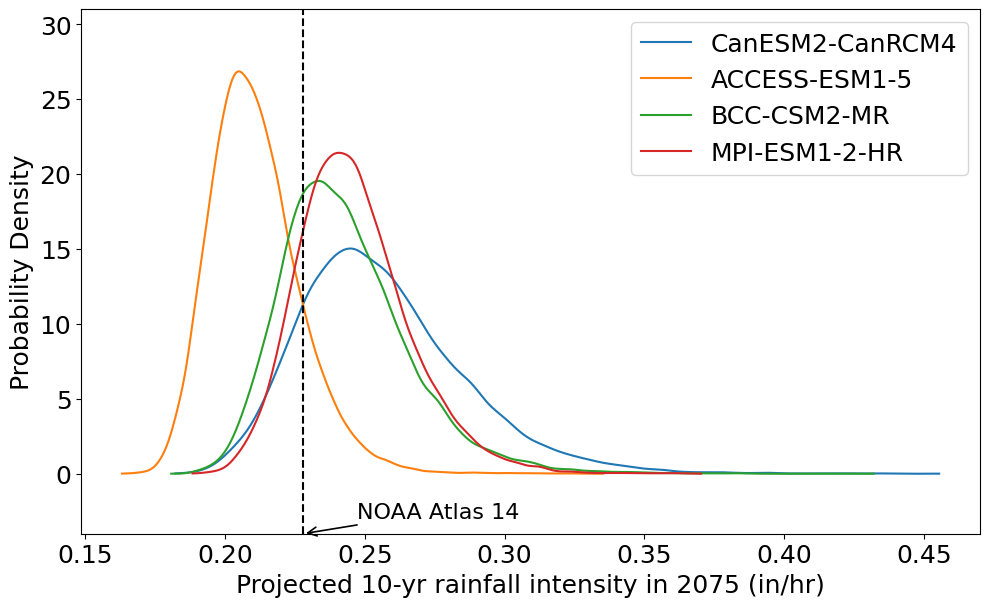

In [18]:
plot_prec_projections(
        setup=s1_setup,
        noaa_file=s1_noaa_file,
        projection_folder=s1_projection_folder,
        figure_name=s1_figure_name,
        return_period=s1_return_period,
        year=s1_year
    )

## Figure S2

Starting reading data...
Data reading completed.

(a) - Metric 0:
Reference mean value: 66.43800000000002, Lower bound: 64.77705000000002, Upper bound: 68.09895000000002
Sample size 1 does not meet the precision requirement. 95% CI: [25.00, 62.50]
Sample size 12 does not meet the precision requirement. 95% CI: [60.42, 72.42]
Sample size 25 does not meet the precision requirement. 95% CI: [63.00, 70.00]
Sample size 50 does not meet the precision requirement. 95% CI: [64.62, 70.13]
Sample size 125 (1000 SOWs) meets the precision requirement with 95% CI: [65.00, 68.00]
Sample size 175 (1400 SOWs) meets the precision requirement with 95% CI: [65.57, 67.76]
Sample size 250 (2000 SOWs) meets the precision requirement with 95% CI: [65.22, 67.45]
Sample size 1250 (10000 SOWs) meets the precision requirement with 95% CI: [66.15, 66.73]

(b) - Metric 1:
Reference mean value: 8.72565356045897, Lower bound: 7.853088204413073, Upper bound: 9.598218916504868
Sample size 1 does not meet the precision

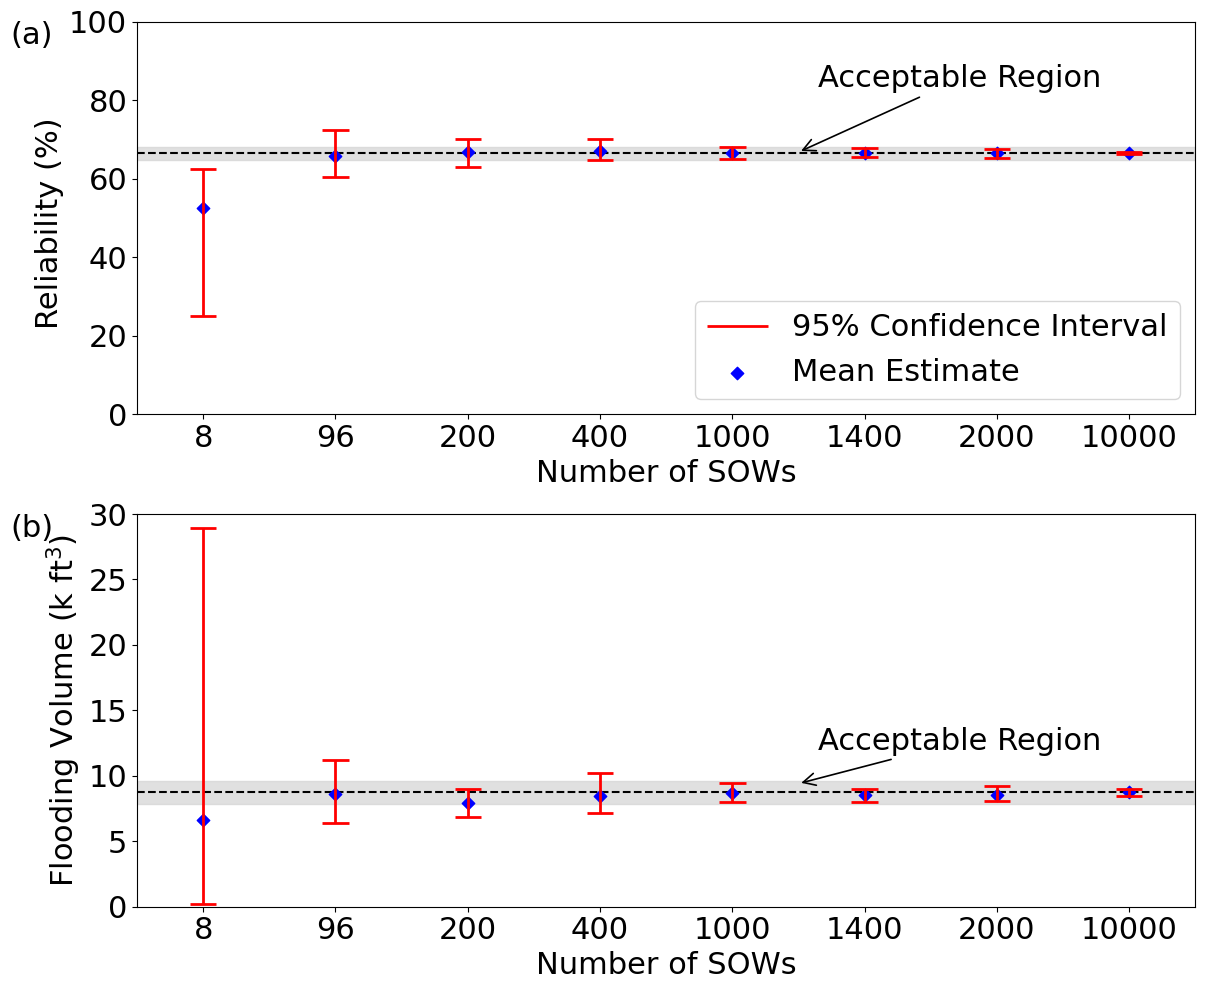

In [19]:
plot_sow_count_rel(
        setup=s2_setup,
        samples_folder=s2_samples_folder,
        figure_name=s2_figure_name,
        network=s2_network,
        num_SOWs=s2_num_SOWs,
        num_resample=s2_num_resample,
        rel=s2_rel,
        seeds=s2_seeds
    )

## Figure S3

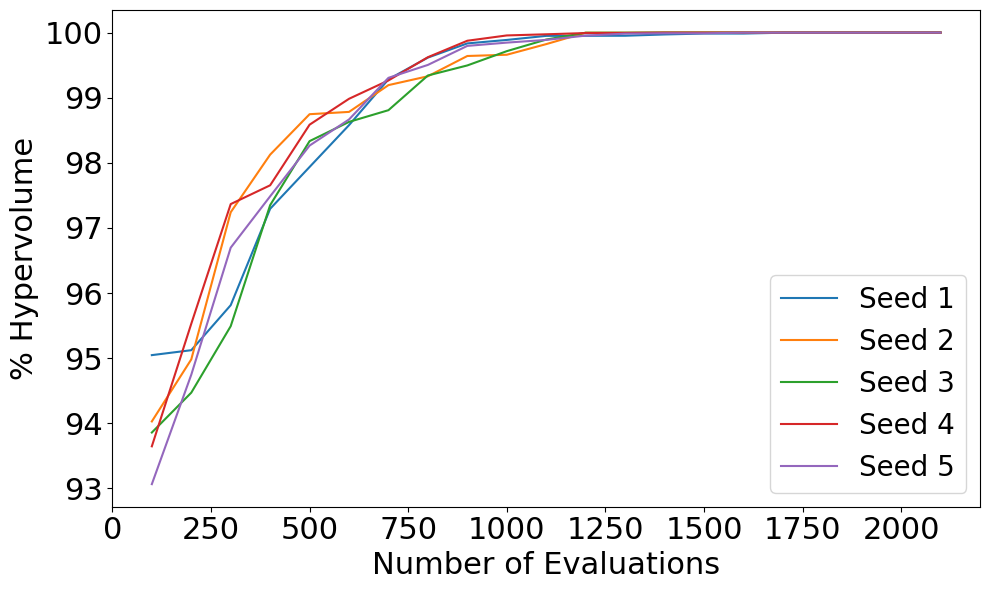

In [20]:
plot_ga_hv(
    folder=s3_folder,
    seeds=s3_seeds,
    gaSettings=s3_gaSettings,
    n_objs=s3_n_objs,
    figure_name=s3_figure_name
)

## Figure S4

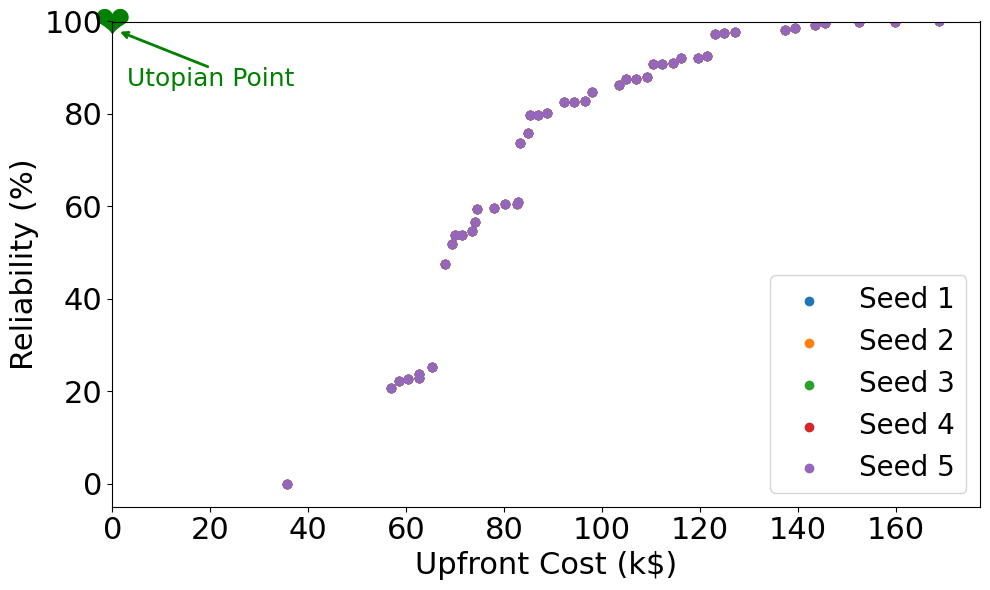

In [21]:
plot_ga_obj(
    folder=s4_folder,
    seeds=s4_seeds,
    gaSettings=s4_gaSettings,
    n_objs=2,
    figure_name=s4_figure_name
)

## Figure S6

Reading UDD data...
Network 5: 79.80% reliability
Network 9: 79.40% reliability
Network 16: 69.60% reliability
Network 23: 69.60% reliability
Network 37: 65.60% reliability
Network 49: 80.60% reliability
Network 62: 63.70% reliability
Network 76: 64.40% reliability
Network 84: 61.60% reliability
Estimated reliability for network 100: 60.44%
Estimated reliability for network 150: 53.62%
Estimated reliability for network 100: 73.59%
Estimated reliability for network 150: 54.38%
Estimated reliability for network 100: 24.55%
Estimated reliability for network 150: 34.54%
Estimated reliability for network 100: 99.20%
Estimated reliability for network 150: 98.77%
Estimated reliability for network 100: 47.33%
Estimated reliability for network 150: 30.09%
Estimated reliability for network 100: 89.75%
Estimated reliability for network 150: 76.48%
Estimated reliability for network 100: 34.44%
Estimated reliability for network 150: 37.75%
Estimated reliability for network 100: 86.17%
Estimated rel

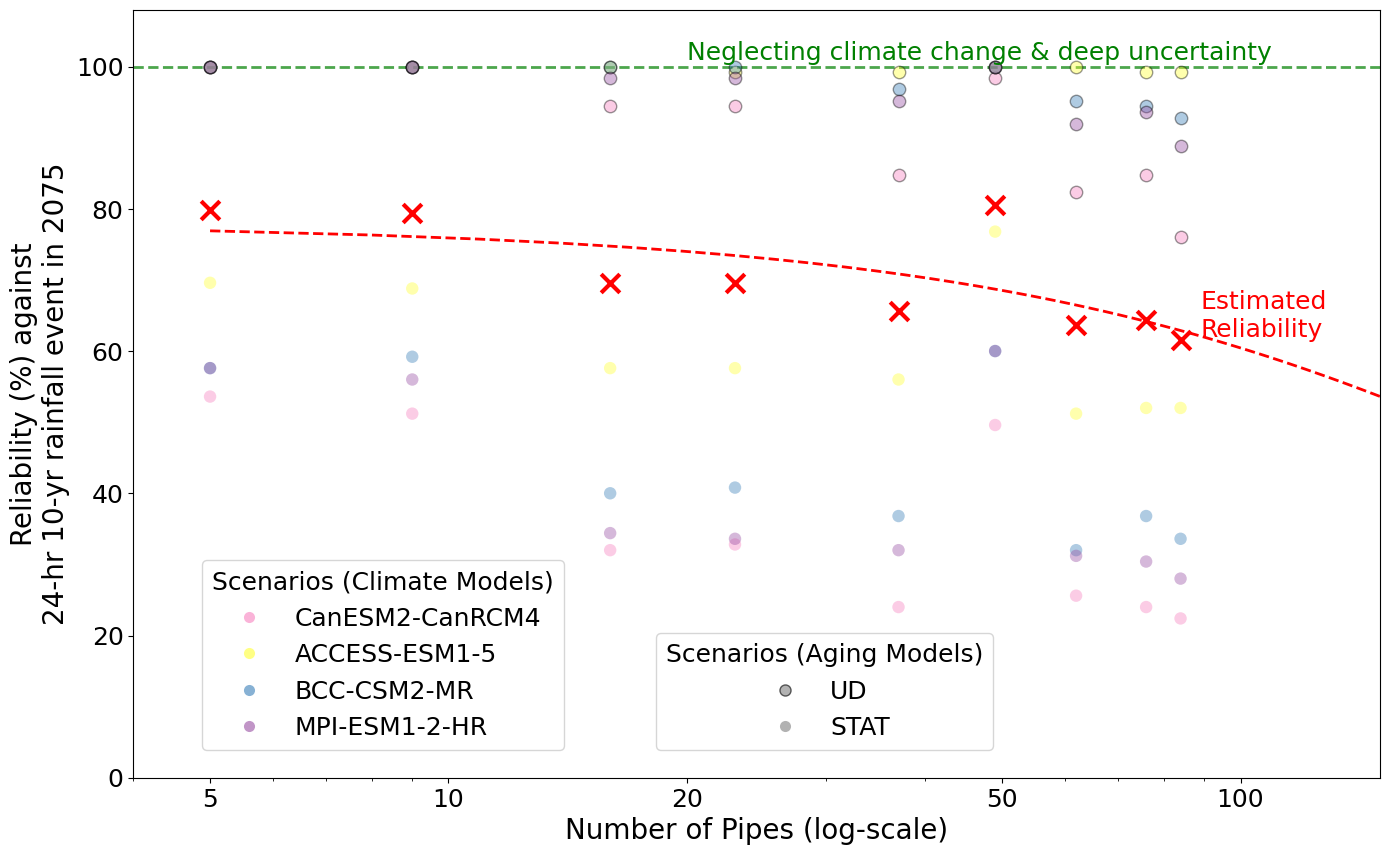

In [22]:
reliabilities, network_sizes = plot_udd_reliability(
        figure_name=s6_figure_name,
        networks=s6_networks,
        swmm_folder=s6_swmm_folder,
        show_plot=True,
        estimated_scenario=s6_estimated_scenario
    )

## Figure S7

UDD matched in SystemSF results. System SF = 1.0011
UDD design details from SystemSF results: {'Reliability (%)': 65.60000000000001, 'Robustness (%)': 50.0, 'System overflow volume (ft^3)': 8866.390020254541, 'Cost ($)': 1040720.1464722704, 'System SF': 1.001100461275199, 'Cost ($/ft)': 164.52096609297067}
UDD 20% precipitation matched in SystemSF results. System SF = 1.0754
UDD 20% precipitation design details from SystemSF results: {'Reliability (%)': 77.3, 'Robustness (%)': 50.0, 'System overflow volume (ft^3)': 6107.231368214223, 'Cost ($)': 1157630.3154525585, 'System SF': 1.075404598341141, 'Cost ($/ft)': 183.00256656157651}


Plotting Reliability (%): x_sorted length = 123, y_sorted length = 123
Plotting Robustness (%): x_sorted length = 123, y_sorted length = 123
Plotting System overflow volume (ft^3): x_sorted length = 123, y_sorted length = 123
Plotting Cost ($/ft): x_sorted length = 123, y_sorted length = 123
System SF closest to 90% reliability: 1.2153
Design details at this point: {'Reliability (%)': 90.2, 'Robustness (%)': 62.5, 'System overflow volume (ft^3)': 2580.4255375385, 'Cost ($)': 1419088.717050447, 'System SF': 1.21529688731093, 'Cost ($/ft)': 224.33489684250534}


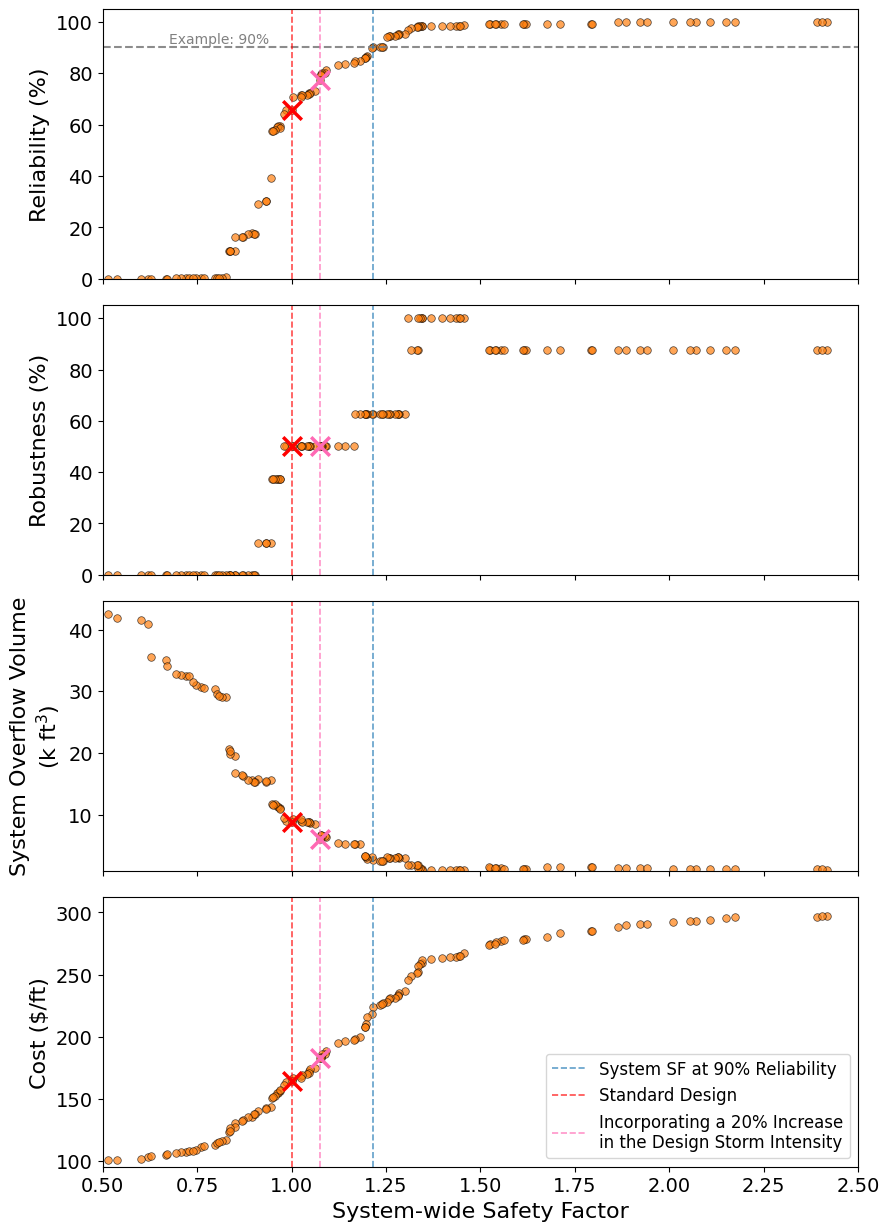

In [23]:
plot_obj_sf(
    figure_name=s7_name,
    n_obj=s7_n_obj,
    network=s7_network,
    SystemSF=True,
    UDD=True,
    UDD_20prec=True,
    swmm_folder=s7_swmm_folder,
    cost_per_ft=True,
    sf_range=(0.50, 2.5))

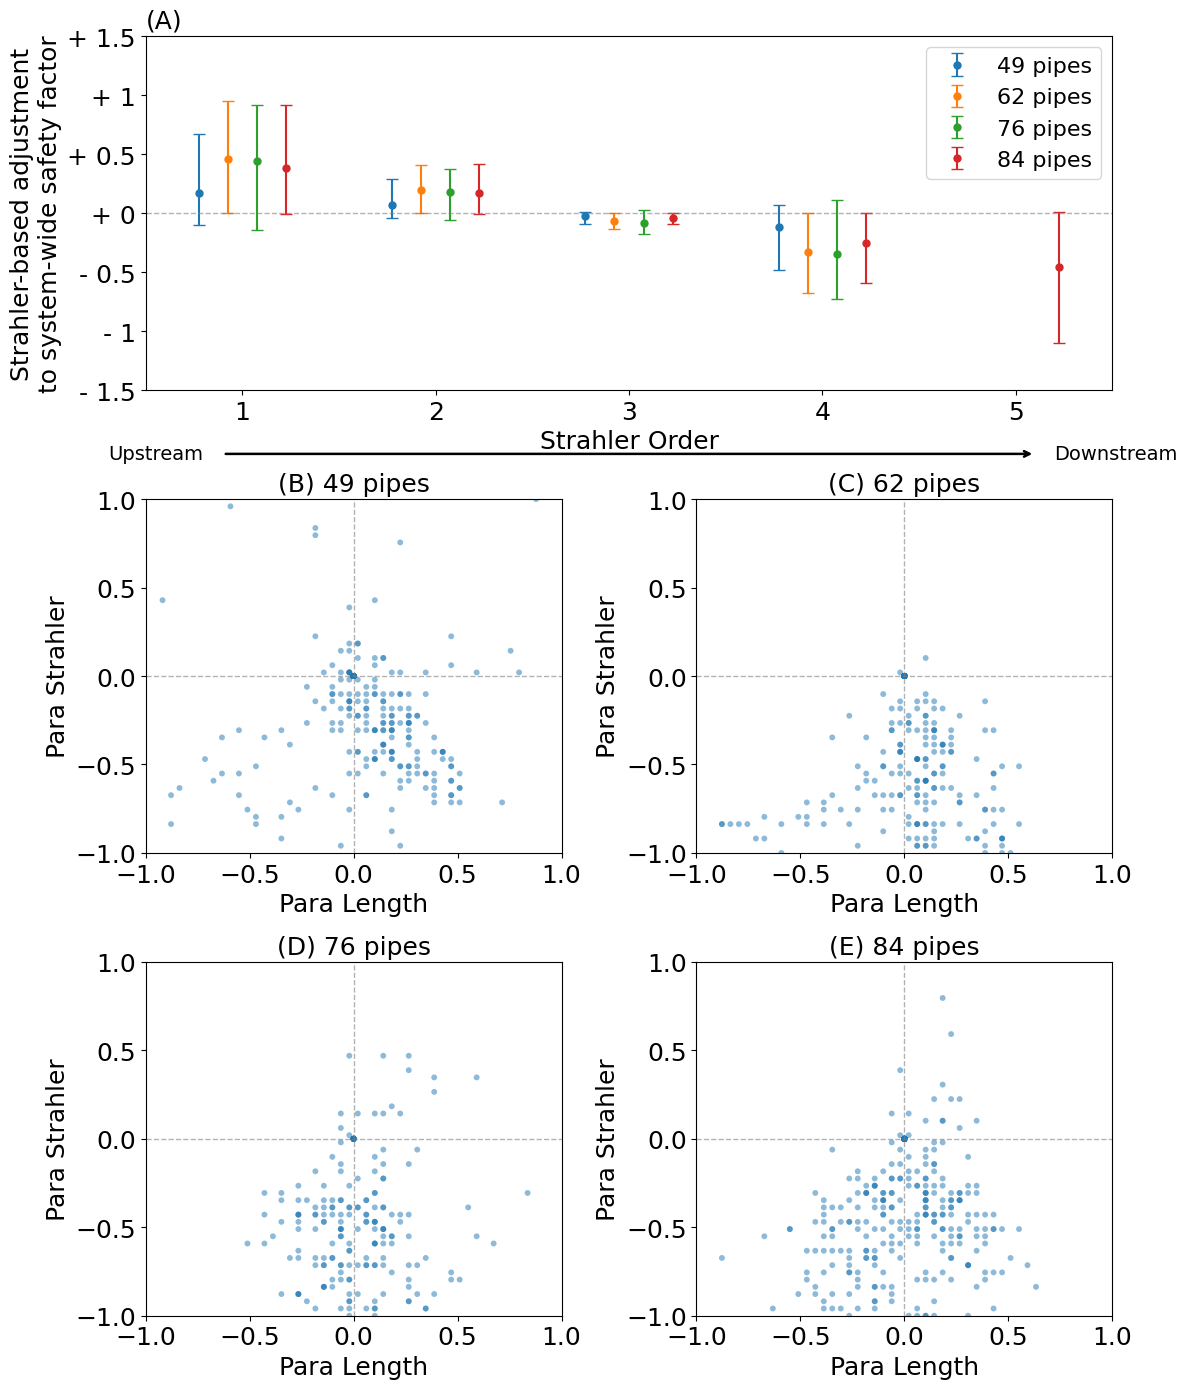

In [24]:
plot_functionsf_parameter_distribution(
    networks = s7_fsf_network,
    output_folder = s7_fsf_folder,
    paths=s7_fsf_path,
    figure_name=s7_fsf_name,
    x_col="Para Length",
    y_col="Para Strahler"
)

## Figure S8

Global cost range across all networks: min=0.00, max=368.01


/tmp/ipykernel_3967583/3189660635.py:122: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.annotate(f'SF: {min_cost_row["System SF"]:.2f}',
/tmp/ipykernel_3967583/3189660635.py:122: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.annotate(f'SF: {min_cost_row["System SF"]:.2f}',
/tmp/ipykernel_3967583/3189660635.py:122: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.annotate(f'SF: {min_cost_row["System SF"]:.2f}',
/tmp/ipykernel_3967583/3189660635.py:122: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.annotate(f'SF: {min_cost_row["System SF"]:.2f}',
/tmp/ipykernel_3967583/3189660635.py:122: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.annotate(f'SF: {min_cost_row["System SF"]:.2f}',
/tmp/ipykernel_3967583/3189660635.py:122: Use

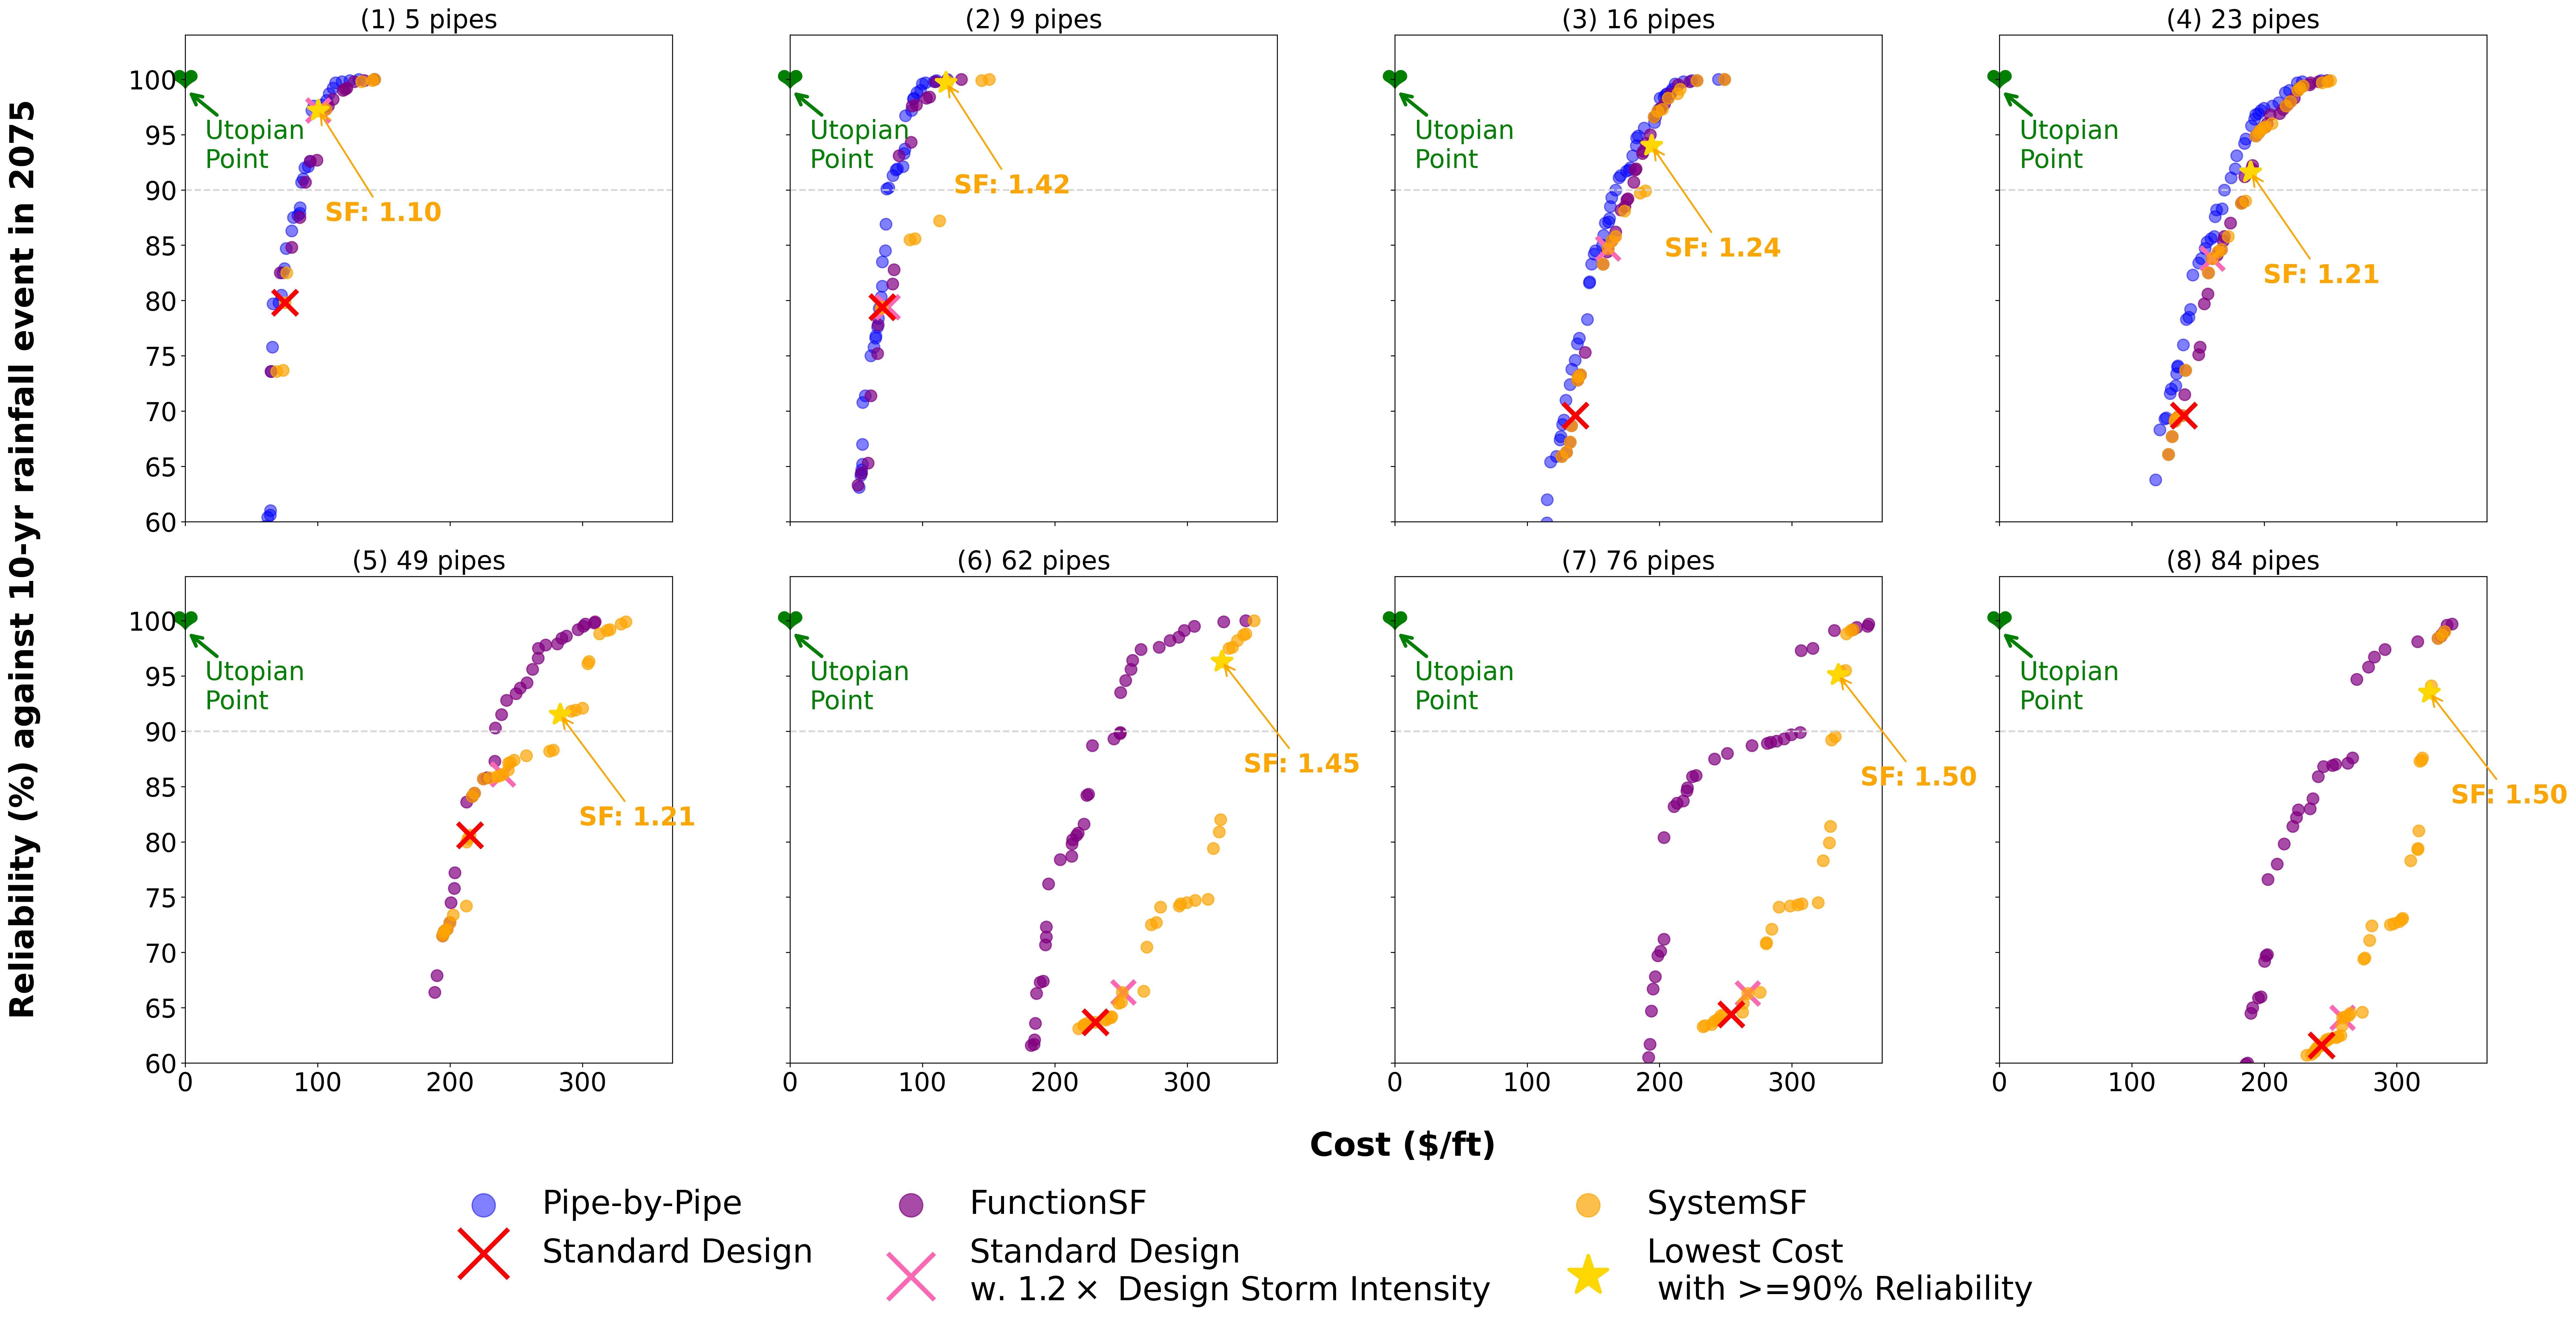

In [25]:
plot_obj_multi_network(
    s8_figure_name, s8_n_obj, s8_paths, cost_per_ft = True, networks = ['5','9','16','23', '49', '62','76','84'], UDD = True, UDD_20prec = True, figure_settings = [2,4]
)

## Figure S9

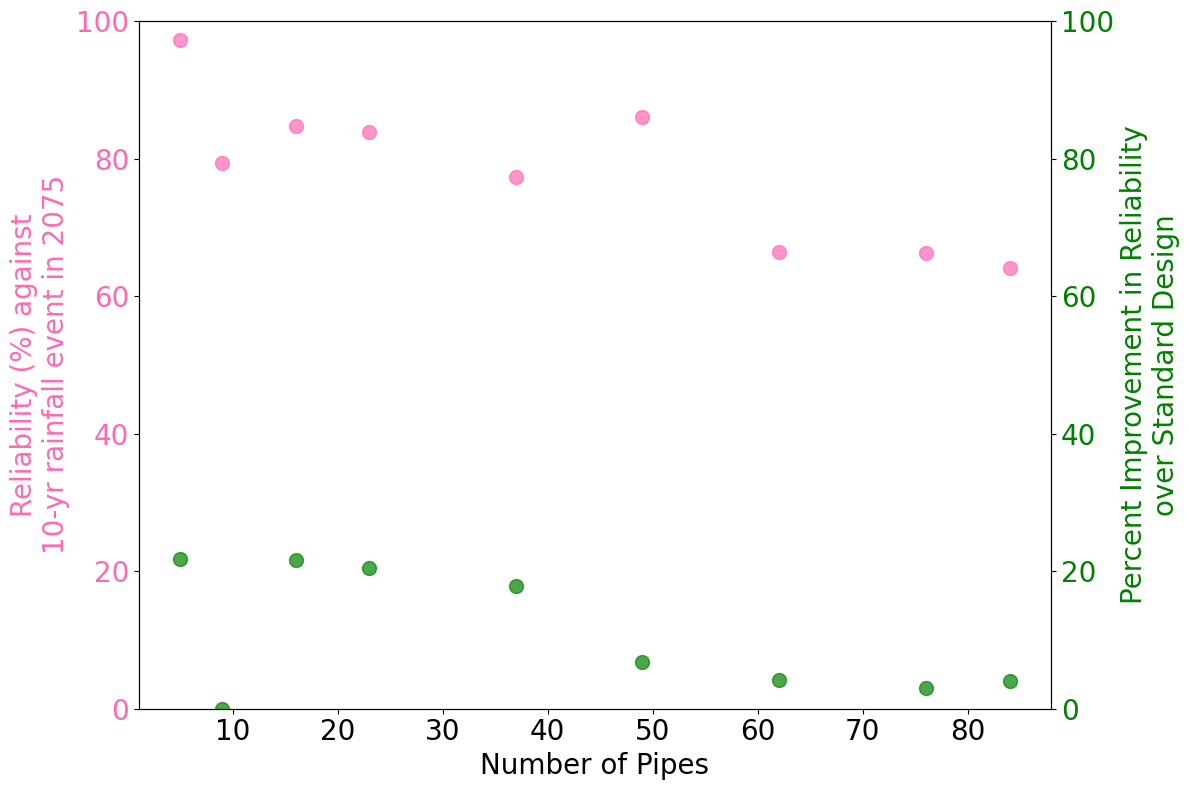

In [26]:
pipes_reliability(networks=s9_networks, paths=s9_paths, figure_name=s9_figure_name)

## Figure S10

In [27]:
SAr_all = read_sobol_results(s10_sobol_json_path_all)
SAr = read_sobol_results(s10_sobol_json_path)

SAr_all_100 = {k1: {k2: (np.array(v) * 100).tolist() for k2, v in obj.items()} for k1, obj in SAr_all.items()}
SAr_100 = {k1: {k2: {k3: (np.array(v) * 100).tolist() for k3, v in inner.items()} for k2, inner in outer.items()} for k1, outer in SAr.items()}

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x

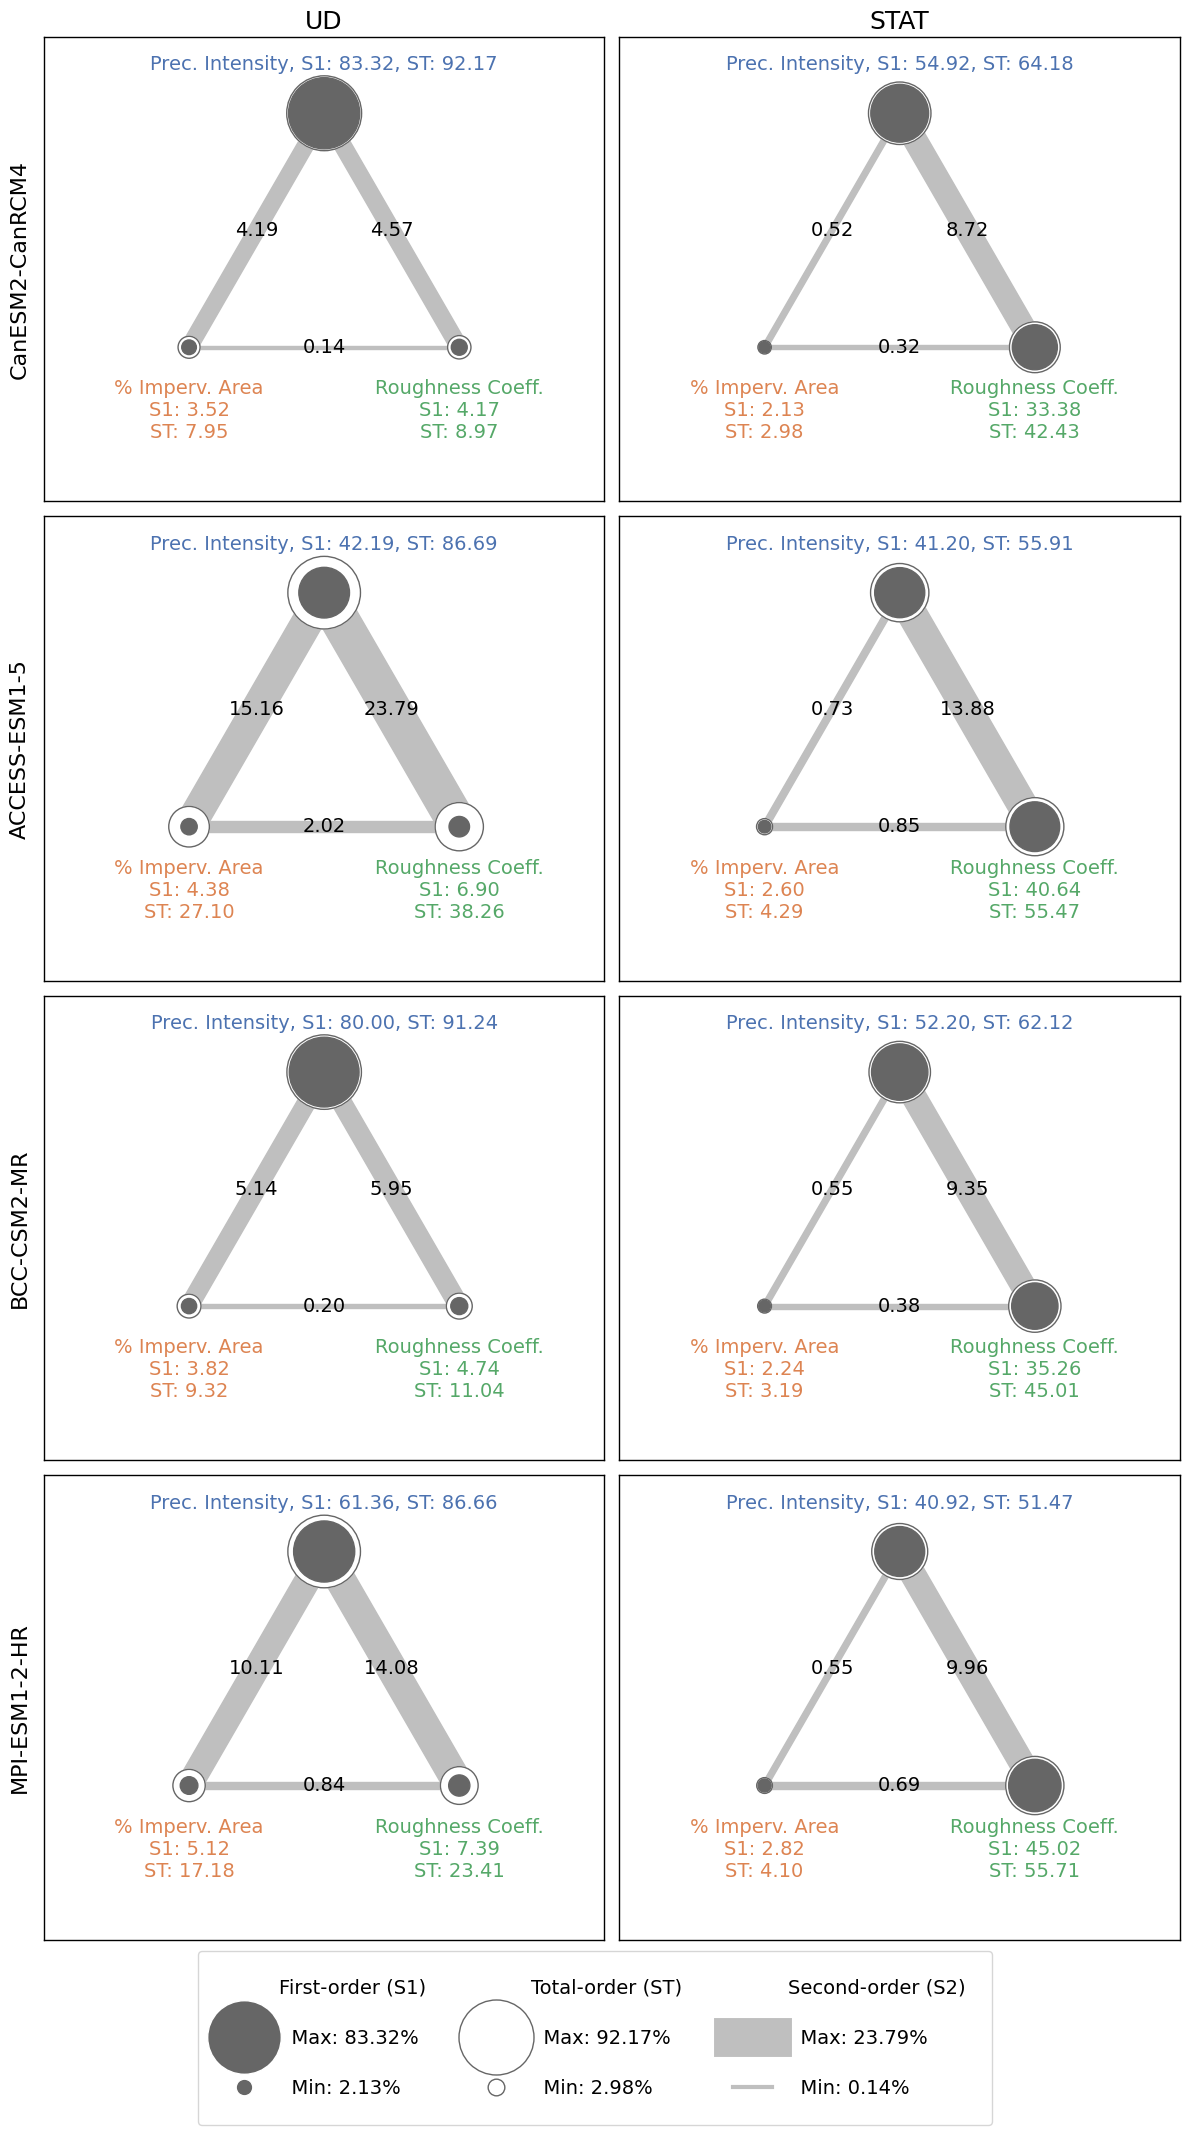

In [28]:
fig, axes = plt.subplots(4, 2, figsize=(12, 20), subplot_kw={'aspect': 'equal'})
fig.tight_layout(pad=4.0)

climate_models = ['CanESM2-CanRCM4', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'MPI-ESM1-2-HR']
aging_models = ['udd', 'stat']

# --- Data and Parameters ---
parameter_names = ['Precipitation Intensity', '% Impervious Area', 'Pipes Manning\'s \nRoughness Coefficient']
parameter_short_forms = ['Prec. Intensity', '% Imperv. Area', 'Roughness Coeff.']
climate_models_subset = ['CanESM2-CanRCM4', 'ACCESS-ESM1-5']
aging_models_subset = ['udd', 'stat']

grouped_para={
    'Climate': ['Precipitation Intensity'],
    'Human Activity': ['% Impervious Area'],
    'Engineering': ['Pipes Manning\'s \nRoughness Coefficient']
}
grouped_para_short={
    'Climate': ['Prec. Intensity'],
    'Human Activity': ['% Imperv. Area'],
    'Engineering': ['Roughness Coeff.']
}

# Find min/max SA values for legend scaling
all_s1 = []
all_st = []
all_s2 = []
for cm in climate_models:
    for am in aging_models:
        sa_results = SAr[f'{cm}_{am}']['System overflow volume']
        all_s1.extend(sa_results['S1'])
        all_st.extend(sa_results['ST'])
        all_s2.extend(s2_val for row in sa_results['S2'] for s2_val in row if s2_val is not None)

s1_min, s1_max = min(all_s1), max(all_s1)
st_min, st_max = min(all_st), max(all_st)
s2_min, s2_max = np.nanmin(all_s2), np.nanmax(all_s2)

# Plotting loop for 4 rows (climate models) and 2 columns (aging models)
for i, cm in enumerate(climate_models):
    for j, am in enumerate(aging_models):
        ax = axes[i, j]
        sa_key = f'{cm}_{am}'
        grouped_radial_text(
            SAr[sa_key]['System overflow volume'],
            parameter_short_forms,
            parameter_short_forms,
            ax,
            groups=grouped_para_short,
            threshold=0.0010,
            varNameMult=1.25,
            fontsize=14,
            print_percentage=True,
            print_numbers=True,
        )
        for spine in ax.spines.values():
            spine.set_edgecolor("black")
            spine.set_linewidth(1)

# Set column titles (aging models) on the top row
axes[0, 0].set_title('UD', fontsize=18)
axes[0, 1].set_title('STAT', fontsize=18)

# Set row titles (climate models) on the left
for i, cm in enumerate(climate_models):
    axes[i, 0].set_ylabel(cm, fontsize=16, labelpad=10)

# Create legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='First-order (S1)'),
    Line2D([0], [0], marker='o', color='w', label=f'  Max: {s1_max*100:.2f}%', markerfacecolor='0.4', markersize=53),
    Line2D([0], [0], marker='o', color='w', label=f'  Min: {s1_min*100:.2f}%', markerfacecolor='0.4', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Total-order (ST)'),
    Line2D([0], [0], marker='o', color='w', label=f'  Max: {st_max*100:.2f}%', markerfacecolor='w', markeredgecolor='0.4', markersize=54),
    Line2D([0], [0], marker='o', color='w', label=f'  Min: {st_min*100:.2f}%', markerfacecolor='w', markeredgecolor='0.4', markersize=12),
    Line2D([0], [0], marker='o', color='w', label='Second-order (S2)'),
    Line2D([0], [0], color='0.75', lw=28, label=f'  Max: {s2_max*100:.2f}%'),
    Line2D([0], [0], color='0.75', lw=3, label=f'  Min: {max(0,s2_min)*100:.2f}%'),
]

fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.07), ncol=3, fontsize=14, labelspacing=1.6, columnspacing=2.6, borderpad=1.4)

plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.savefig(s10_figure_name, dpi=300)
plt.show()

## Figure S11

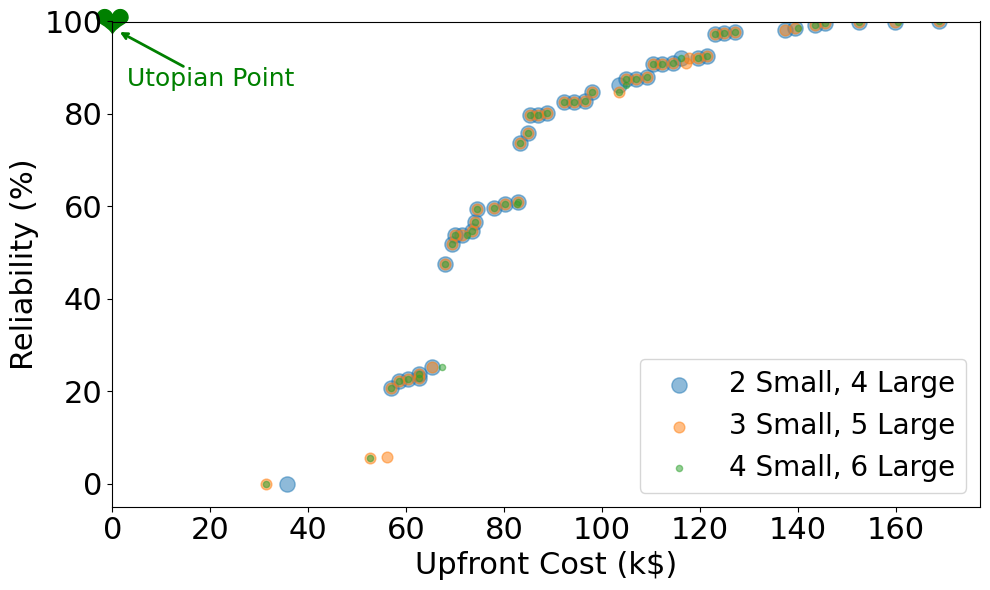

In [29]:
plot_ga_obj_size_choice(s11_folder, [[2,4],[3,5], [4,6]], [120,60,20], s11_gaSettings, n_objs=2, figure_name=s11_figure_name, cost_vs_reliability=False, bf_path=None)
